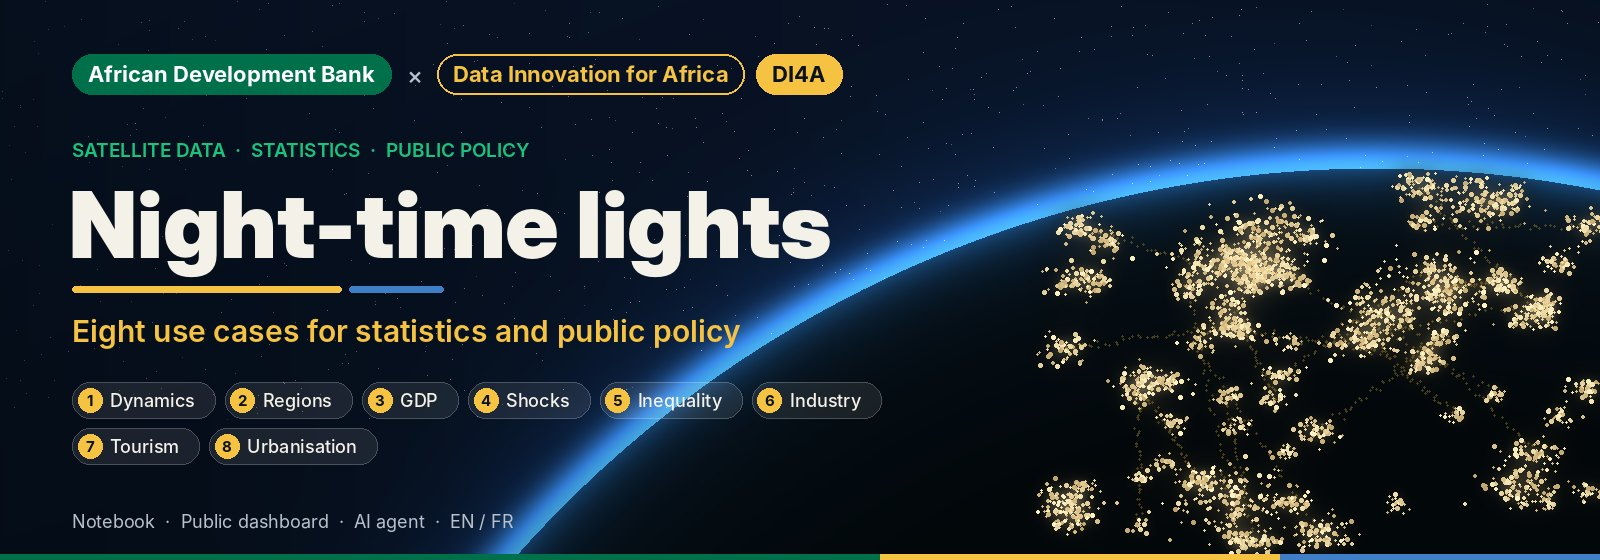

# 🛰️ Night-time lights: eight use cases for statistics and public policy

**African Development Bank** &nbsp;×&nbsp; **Data Innovation for Africa (DI4A)**

> ©️ **© 2026 AfDB-DI4A — source attribution required.** Any reproduction or reuse of this notebook, its results or
> the dashboard built from it must state the source: **“Source: AfDB-DI4A”** (full terms at the end of the notebook).

> **Eight professional use cases · public dashboard · AI assistant**
>
> A reproducible pipeline, driven by an ISO3 code, that uses night-time lights observed by satellite, combined with
> complementary data (population, built-up area, pollution, land-surface temperature, national accounts), to answer
> **eight statistical and public-policy questions**: economic dynamics, regional growth, the link with GDP, shocks and
> resilience, inequality and electrification, industrial zones, seasonal tourism, urbanisation. The results are published on a public
> web dashboard and an AI agent answers only from these results.

Runs on **Google Colab**, **Kaggle** and **local Jupyter** ·
requires a **Google Earth Engine** project (or `SYNTHETIC_TEST = True` for a trial without Earth Engine).

| | |
|---|---|
| **Input** | an ISO3 country code (e.g. `TUN`, `SEN`, `KEN`) and a period |
| **Data** | VIIRS (monthly, annual), DMSP-OLS, daily Black Marble, GHSL (population, non-residential built-up), WorldPop, Sentinel-5P (NO₂, SO₂), MODIS (land surface temperature), OpenStreetMap, World Bank (GDP, industry value added, access to electricity) |
| **Outputs** | 8 use cases: dynamics, regional growth, NTL–GDP, shocks, inequality and electrification, industrial zones, seasonal tourism, urbanisation |
| **Deliverables** | a bilingual dashboard (EN/FR) published on GitHub Pages in a single call, and an AI assistant (Groq, Gemini or Ollama) in the notebook and on the site |

> ℹ️ **How to read this notebook** — The table of contents (☰ icon on the left in Colab) lists the 19 sections; each
> can be collapsed. Each section opens with a box: 🎯 objective, 📚 key concepts, 🛠️ method, 🔎 key takeaways. The
> interpretations at the end of each section are **generated from the results** for the country studied, with a
> confidence level. A French version of this notebook is available (`NTL_8_use_cases_FR.ipynb`).

---

<sub>**SECTION 00 / 18**</sub>

## 📋 0. Executive summary

*Key messages generated automatically, each with its confidence level*

> The key messages below (one or two per use case) are **generated automatically** at the end of the run
> (section 13) from the results. Each message carries a confidence level — 🟢 high, 🟠 medium, 🔴 low —
> and the reason for it. On the first run, the cell shows a placeholder, filled in as soon as section 13 has run.

In [ ]:
from IPython.display import display, Markdown
EXEC_SUMMARY = display(Markdown("*The executive summary will appear here once section 13 has run.*"),
                       display_id="exec-summary")

---

<sub>**SECTION 01 / 18**</sub>

## 💡 1. Introduction: what night-time lights can measure — eight use cases

*What the lights measure — and what they do not tell us*

> 🎯 **Objective** — Understand what night-time lights (NTL) measure, why they are informative about economic
> activity, and where the limits of what they can tell us lie.

**The intuition.** Producing, transporting, trading and consuming all require energy, and part of that energy
escapes at night as light that is visible from space. The more active an area, the brighter it shines. Satellite
sensors measure this light everywhere, every night, with the same method: it is a **consistent, spatially detailed and
timely** indicator, whereas national accounts are annual, published with a lag and rarely available at regional level.

**What the literature says.**
- *Henderson, Storeygard & Weil (2012, AER)* — growth in lights tracks GDP growth; the elasticity of GDP with respect to
  lights is about 0.3; lights improve growth estimates where statistics are weak.
- *Chen & Nordhaus (2011, PNAS)* — lights add information mainly for countries with weak statistics
  and for subnational regions.
- *Elvidge et al. (2017, 2021)* — monthly and annual VIIRS products (VNL V2): stray-light correction,
  background and ephemeral-light masks.
- *Román et al. (2018)* — NASA Black Marble: BRDF and lunar correction, suited to daily series.
- *Li et al. (2020, Scientific Data)* — harmonised DMSP–VIIRS series 1992–2021.
- *Gibson, Olivia & Boe-Gibson (2020-2021)* — limitations of lights in rural and sparsely populated areas.

**What they do not tell us.** Lights measure *radiance* at around 01:30, not value added.
Agriculture, daytime trade, a large share of services and the rural informal economy are barely visible.
Section 13 and the dashboard's “Methods & limitations” page set out these biases in detail. This is why each use case
**cross-checks light against another source** (population, built-up areas, pollution, heat, national accounts, hotel
nights) and reports a confidence level.

**Two generations of sensors.**

| Sensor | Period | Resolution | Measure | Use here |
|---|---|---|---|---|
| DMSP-OLS | 1992–2013 | ~1 km | digital number 0–63, saturates in cities | long series (harmonised version), diagnostics |
| VIIRS DNB | 2012 → | ~500 m | calibrated radiance (nW·cm⁻²·sr⁻¹) | all main analyses |
| Black Marble VNP46A2 | 2012 → | ~500 m, **daily** | BRDF/moon-corrected radiance | detailed analysis of shocks |

**The eight use cases.** Each one answers a question asked by an economist, a statistician or a policymaker.

| # | Use case | Policy question | Light + complementary data | Section |
|---|---|---|---|---|
| 1 | 📈 **Temporal dynamics** | Is activity accelerating or slowing down, net of seasonal effects? | Monthly VIIRS, harmonised DMSP–VIIRS series | 5 |
| 2 | 🗺️ **Regional growth and convergence** | Which regions are taking off, and which are falling behind? | Annual VIIRS, GHSL/WorldPop population, NO₂ | 6 |
| 3 | 💹 **NTL–GDP relationship** | Can growth be estimated before it is published, and can regional GDP be estimated? | VIIRS, real GDP (World Bank) | 7 |
| 4 | ⚡ **Shocks and resilience** | How deep was a shock, and how did recovery unfold? | Monthly VIIRS, daily Black Marble, event catalogue | 8 |
| 5 | ⚖️ **Inequality and electrification** | Where do people without electricity live? | VIIRS, population, degree of urbanisation, WDI access | 9 |
| 6 | 🏭 **Industrial zones** | Where is industry located, and is its activity increasing? | VIIRS + GHSL non-residential built-up + Sentinel-5P NO₂/SO₂ + MODIS heat, validated against OSM | 10 |
| 7 | 🏖️ **Seasonal tourism** | Which areas depend on tourism, and how is the season evolving? | Monthly VIIRS, comparable areas, Ramadan calendar, hotel nights | 11 |
| 8 | 🏙️ **Urbanisation** | Where do cities spread, where do villages light up, and where does population grow without light? | Annual VIIRS (lit area), GHSL population and built-up, WDI urbanisation rate | 12 |

**From the notebook to the public.** Each result receives a **quality sheet** that complies with international standards
(section 14: UN, DQAF, GSBPM, FAIR). The results are exported (section 15) to a **bilingual
dashboard**, illustrated with **real images and animations** of the country (section 16). An **AI agent** (section 17), available
here and on the site, uses tools to rank, compare, draw charts, control the map and write
briefs, *citing the computed figures*. Finally (section 18), a single call publishes the site on GitHub Pages **and** a
showcase GitHub repository (illustrated README, documentation, citation).

```
 Satellites + data           Notebook (this document)                          Public
 ─────────────────────       ──────────────────────────────────────            ──────────────────────────────────
 VIIRS · Black Marble  ──►   acquisition ► 8 use cases ► quality      ──►      dashboard (GitHub Pages)
 GHSL · S5P · MODIS    ──►   (cache, checks)    ► export ► images     ──►      showcase GitHub repository (animated README)
 OSM · World Bank      ──►                      ► AI agent            ──►      AI agent (visitor's key / Ollama)
```

---

<sub>**SECTION 02 / 18**</sub>

## ⚙️ 2. Parameters and configuration

*A single cell to edit: the ISO3 code and the period*

> 🎯 **Objective** — Set everything that determines the results in one place, then connect to Google Earth Engine.
>
> 📚 **Key concepts** — *ISO3*: three-letter country code. *ADM1/ADM2*: first and second administrative levels
> (regions, districts). *Earth Engine (GEE)*: Google's computing platform that hosts the satellite imagery;
> computations run server-side and only the aggregated tables are brought back.
>
> 🛠️ **Method** — A single cell to edit (below). The other thresholds are documented default values
> in `src/config.py` and can be overridden in `NTLConfig(...)`. Acquisition results are **cached**:
> a second run does not query Earth Engine again (set `FORCE_DOWNLOAD = True` to force it).
>
> 🔐 **Keys and secrets** — No key is written in the notebook. Earth Engine authenticates through your Google account;
> the assistant's keys (`GROQ_API_KEY`, `GEMINI_API_KEY`) and the GitHub token (`GITHUB_TOKEN`) are read from
> **Colab Secrets** (🔑 icon), an environment variable or a `.env` file, and otherwise requested through masked input.
> They are never displayed, logged, exported or published.
>
> 🔎 **Key takeaways** — Changing `ISO3` is enough to analyse another country: no country-specific value
> is written in the code. To try the notebook without Earth Engine, set `SYNTHETIC_TEST = True`: a fictitious
> country (`XTS`) is generated locally and the whole notebook runs in a few minutes.

In [ ]:
# --- 2.0 Embedded project code (src/ + dashboard/, zip, base64) — generated, do not edit ---
# Lets the notebook run alone (e.g. opened directly in Colab). Regenerate with scripts/build_notebook.py.
PROJECT_BUNDLE = """
...
CwAAAA==
"""

In [ ]:
# --- 2.1 Environment: project code + missing packages (Colab / Kaggle / local) ----------
# The notebook is SELF-CONTAINED: if the src/ folder is not next to it (e.g. the .ipynb was
# opened alone in Colab), the project code embedded below is unpacked automatically.
import importlib.util, subprocess, sys, os, io, base64, zipfile
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
# A cloned repository (src/ next to the notebook) is used as is. Otherwise, the embedded code is ALWAYS
# unpacked again: an old copy left in /content (the Colab session keeps files after
# “Restart session”) must never hide the notebook's version.
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "src" / "pipeline.py").exists()), None)
if ROOT is None:
    ROOT = Path("/content/ntl-economic-analysis") if IN_COLAB else Path.cwd() / "ntl-economic-analysis"
    ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(PROJECT_BUNDLE))) as z:
        z.extractall(ROOT)   # overwrites src/ and dashboard/; outputs/ (cache) is kept
    print(f"Project code (src/, dashboard/) unpacked into {ROOT}")

NEEDED = {"ee": "earthengine-api", "geemap": "geemap", "geopandas": "geopandas", "statsmodels": "statsmodels",
          "plotly": "plotly", "folium": "folium", "pycountry": "pycountry", "ruptures": "ruptures",
          "dotenv": "python-dotenv", "ipywidgets": "ipywidgets", "requests": "requests"}
missing = [pkg for mod, pkg in NEEDED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", ", ".join(missing))
    if subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False).returncode:
        for pkg in missing:   # one failing package must not block the others
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
importlib.invalidate_caches()
print("Project root:", ROOT)

# Colab: the maps (geemap / ipyleaflet) are “third-party” widgets. Colab's custom widget manager is enabled
# here; otherwise Colab opens the “Code snippets › Third-party Jupyter widgets” panel.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

In [ ]:
# ======================================================================================
# ⚙️  PARAMETERS — the only cell to edit
# ======================================================================================
ISO3 = "TUN"                 # ISO 3166-1 alpha-3 country code
START_YEAR = 2014            # first full year of monthly VIIRS
END_YEAR = None              # None -> last full year available in GEE
ADMIN_LEVELS = ("ADM1", "ADM2")
GEE_PROJECT = None           # Google Cloud project ID; None -> EE_PROJECT variable or prompt
FORCE_DOWNLOAD = False       # True -> ignore the cache and query Earth Engine again

# Country-specific events (conflicts, disasters, energy crises, electrification…)
CUSTOM_EVENTS = [
    # {"label": "Cyclone X", "start": "2019-03-01", "end": "2019-05-31", "type": "catastrophe"},
]
DAILY_WINDOWS = [            # Black Marble daily analysis windows (in addition to COVID-19)
    # {"id": "cyclone_x", "label": "Cyclone X", "start": "2019-02-01", "end": "2019-07-31"},
]
EVENTS_CSV = None            # optional ACLED/EM-DAT export (see src/shocks.py)

# Use case 6 — industrial zones (section 10)
INDUSTRY_YEAR = None         # cluster detection year; None -> last year
INDUSTRIAL_REFERENCE = None  # official CSV of industrial zones (columns name, lon, lat); None -> OpenStreetMap
INDUSTRY_PARAMS = {}         # threshold overrides, e.g. {"rad_min": 8, "min_signals": 4} (see src/industry.py)

# Use case 7 — seasonal tourism (section 11)
TOURISM_STATS_CSV = None     # CSV of hotel nights (columns year, nights_millions); None -> WDI arrivals (ST.INT.ARVL)
TOURISM_PARAMS = {}          # overrides, e.g. {"peak_months": (7, 8), "min_excess": 0.15} (see src/tourism.py)

# AI agent (section 17) — keys are read from Colab Secrets / the environment, never written here
AGENT_PROVIDER = "groq"      # "groq" (default) | "gemini" | "ollama" | "auto" | "local" (planner without LLM)
#   Groq key: Colab Secrets (🔑, name GROQ_API_KEY); otherwise it is ASKED FOR AS MASKED INPUT in section 17
#   (free at https://console.groq.com/keys). Empty input -> the agent switches to offline mode.
# Model used with each provider (editable). Other possible choices:
#   Groq   : "openai/gpt-oss-120b" (default, 120B-parameter open model), "llama-3.3-70b-versatile",
#            "meta-llama/llama-4-scout-17b-16e-instruct", "llama-3.1-8b-instant" (fastest)
#   Gemini : "gemini-2.5-flash" (default), "gemini-2.5-pro" (finer, smaller free quota), "gemini-2.5-flash-lite"
GROQ_MODEL = "openai/gpt-oss-120b"
GEMINI_MODEL = "gemini-2.5-flash"
OLLAMA_IN_COLAB = False      # True -> installs and starts Ollama in the Colab session (GPU recommended)
OLLAMA_MODEL = "qwen2.5:7b"  # Ollama model to download if OLLAMA_IN_COLAB

# Images and animations (section 16)
MAKE_MEDIA = True            # timelapse, before/after, animated shock, cover, vignettes of the 8 use cases
CAPTURE_DASHBOARD = True     # animated tour of the dashboard (headless browser; ~2 min the first time)

# Publication (section 18)
PUBLISH = True               # True -> publishes the dashboard on GitHub Pages
GITHUB_USER = None           # None -> the token's user
REPO_NAME = "NTL_{COUNTRYNAME}_Project"   # {COUNTRYNAME} -> English country name, e.g. NTL_Tunisia_Project
PUSH_SOURCE = False          # True -> also pushes the code + workflow (“Workflows” permission required)

SYNTHETIC_TEST = False       # True -> fictitious country 'XTS' generated locally: the whole notebook runs without Earth Engine
if SYNTHETIC_TEST:
    ISO3, START_YEAR, END_YEAR = "XTS", 2014, 2025

In [ ]:
# --- 2.2 Imports, configuration, logging ---------------------------------------------------
import logging, warnings, json, datetime as dt
import numpy as np, pandas as pd
import plotly.graph_objects as go, plotly.express as px, plotly.io as pio

from src.config import NTLConfig, DATASETS, package_versions
from src import cache, gee, viz, pipeline as P, indicators as ind, timeseries as ts
from src import messages as M, export as X
from src import industry as IND, tourism as TOU, urban as URB, agent as AG
from src.boundaries import get_boundaries, attach_parents, area_km2

warnings.filterwarnings("ignore", category=FutureWarning)
logging.basicConfig(level=logging.INFO, format="%(message)s")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pio.templates.default = "plotly_white"

def show_md(text):
    display(Markdown(text))

fnum, fpct = M._f, M._pct      # English number formatting: fnum(0.79) -> "0.79"; fpct(0.031) -> "+3.1%"

cfg = NTLConfig(iso3=ISO3, start_year=START_YEAR, end_year=END_YEAR, admin_levels=tuple(ADMIN_LEVELS),
                gee_project=GEE_PROJECT, custom_events=CUSTOM_EVENTS, daily_windows=DAILY_WINDOWS,
                events_csv=EVENTS_CSV, output_dir=str(ROOT / "outputs"), dashboard_dir=str(ROOT / "dashboard"))

# Basemap for the geemap maps. External tile servers (OpenStreetMap, CARTO) reject requests
# coming from Colab (“Access blocked”, “API key required”). The basemap is therefore drawn by
# Earth Engine itself — the same server as the data, which always works in Colab:
# dark sea, dark grey land, national borders (USDOS LSIB).
BASEMAP_NAME = "Earth Engine basemap (borders)"
ESRI_DARK = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}"
ESRI_ATTR = "Tiles © Esri — Esri, HERE, Garmin, © OpenStreetMap contributors"

def ee_basemap():
    """Earth Engine image used as a basemap (no key, no third-party server)."""
    import ee
    lsib = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    sea = ee.Image.constant(0).visualize(min=0, max=1, palette=["0b0f14"])
    land = ee.Image().byte().paint(lsib, 1).visualize(min=0, max=1, palette=["1f2732"])
    borders = ee.Image().byte().paint(lsib, 1, 1).visualize(min=0, max=1, palette=["6b7280"])
    return ee.ImageCollection([sea, land, borders]).mosaic()

def _no_colab_secret_lookup():
    """geemap queries the Colab secret GOOGLE_MAPS_API_KEY for every new map. Outside the interface
    (“Run all”, busy session), this request times out: TimeoutException. So only the environment
    variable is read — the Google Maps key is not needed here."""
    import os
    import geemap.coreutils as gcu
    gcu.get_google_maps_api_key = lambda key="GOOGLE_MAPS_API_KEY": os.environ.get(key)

def make_map(center, zoom=6):
    """geemap map without an external basemap: the default OSM basemap is removed and replaced by ee_basemap()."""
    import geemap
    _no_colab_secret_lookup()
    m = geemap.Map(center=center, zoom=zoom)
    for lyr in list(m.layers):
        url = str(getattr(lyr, "url", ""))
        if url.startswith("http") and "earthengine" not in url:
            m.remove_layer(lyr)
    m.addLayer(ee_basemap(), {}, BASEMAP_NAME)
    return m

In [ ]:
# --- 2.3 Earth Engine: only if a required acquisition step is not cached yet -----------
cfg.resolve()   # validates ISO3 (clear error if unknown); END_YEAR=None -> provisional, refined below
REQUIRED = ["boundaries_ADM0", "boundaries_ADM1", "monthly", "annual"]
NEED_GEE = FORCE_DOWNLOAD or not all(cache.exists(cfg.cache_dir, s) for s in REQUIRED)
GEE_OK = False
if SYNTHETIC_TEST:
    # Fictitious country: every table Earth Engine would produce is generated locally in the cache
    # (boundaries, monthly and annual series, industrial clusters, hotel nights, PNG images…).
    from src import fixture
    fixture.write_fixture(cfg.cache_dir)
    NEED_GEE = False
    print("Test mode: synthetic 'XTS' dataset written to", cfg.cache_dir)
else:
    try:
        gee.init_gee(cfg.gee_project, interactive=NEED_GEE)
        GEE_OK = True
    except gee.GEEError as e:
        if NEED_GEE:
            raise
        print("Earth Engine not initialised — analysis from the cache (interactive GEE maps disabled).")
NEED_GEE = NEED_GEE or (GEE_OK and FORCE_DOWNLOAD)
if GEE_OK and END_YEAR is None:
    cfg.end_year = gee.last_complete_year()
cfg.resolve()
print(f"Country: {cfg.country['name']} ({cfg.iso3}) · period {cfg.start_year}–{cfg.end_year} · "
      f"levels {', '.join(cfg.admin_levels)} · cache {cfg.cache_dir}")
# Country flag (flagcdn.com, public domain): used in the summary, the images, the dashboard and the README
from src.flags import ensure_flag, flag_html
from IPython.display import HTML
ensure_flag(cfg, SYNTHETIC_TEST)
display(HTML(f"<div style='display:flex;align-items:center;gap:6px;font:600 1.25em Segoe UI,system-ui'>"
             f"{flag_html(cfg, 34)}{cfg.country['name']}</div>"))

In [ ]:
# --- 2.4 Check identifiers and temporal availability of every dataset ---------------------
AVAIL = cache.cached(cfg.cache_dir, "availability", lambda: gee.check_availability(DATASETS), force=FORCE_DOWNLOAD)
display(AVAIL)

---

<sub>**SECTION 03 / 18**</sub>

## 🛰️ 3. Data acquisition and pre-processing

*From thousands of satellite images to clean, checked tables*

> 🎯 **Objective** — Turn thousands of satellite images into clean tables: one row per administrative
> unit and per month (or year), after removing everything that is not human activity.
>
> 📚 **Key concepts**
> - **Sum of lights (SoL)**: sum of the pixel radiances in an area. It is an *index*, not an amount of energy.
> - **Cloud-free coverage (`cf_cvg`)**: number of usable observations of a pixel in the month. A pixel that is
>   never observed is not *dark*, it is *missing*.
> - **Gas flares**: gas flaring at oil sites shines as brightly as a city without any local economic
>   activity; it must be masked.
> - **Blooming / saturation**: light “spills over” around cities; DMSP saturates (value 63) in city centres.
>
> 🛠️ **Method (and why)**
>
> | Step | Rule | Rationale |
> |---|---|---|
> | Clouds | pixel valid if `cf_cvg` ≥ `cf_cvg_min` (2); unit-month kept if ≥ 80% of pixels are valid, then rescaled | not to mistake a cloudy month for a recession |
> | Negatives | set to 0 | calibration noise over dark areas |
> | Outliers | absolute cap + spikes > 5 × the pixel's annual median replaced by the median | fires, lightning, reflections |
> | Background | pixels unlit in the VNL V2 annual composite → 0 | EOG already masks background and ephemeral lights there |
> | Gas flares | pixels ≥ 50 nW, < 5 inhabitants, not built-up (union of years) + 2 km halo | removes flared gas and its spillover |
> | DMSP | share of saturated pixels measured; DN > 7 threshold on the harmonised series | recommendation of Li et al. (2020) |
>
> 🔎 **Key takeaways** — The quality-control table (3.4) shows the share of excluded months, the share of light
> removed as gas flares and DMSP saturation. If any of them is high, the corresponding results are less reliable.

In [ ]:
# --- 3.1 Administrative boundaries (geoBoundaries CGAZ, FAO GAUL as fallback) -------------
if GEE_OK:   # server-side collections are needed for zonal statistics and maps
    GDFS, FCS, BMETA = get_boundaries(cfg)
    for lv, g in GDFS.items():
        cache.save(cfg.cache_dir, f"boundaries_{lv}", g)
    cache.save(cfg.cache_dir, "boundary_meta", BMETA)
else:
    GDFS = {lv: cache.load(cfg.cache_dir, f"boundaries_{lv}") for lv in ("ADM0", *cfg.admin_levels)}
    GDFS = attach_parents({k: v for k, v in GDFS.items() if v is not None})
    BMETA, FCS = cache.load(cfg.cache_dir, "boundary_meta") or {}, None
NAMES = P.unit_names(GDFS)
for lv, g in GDFS.items():
    print(f"{lv}: {len(g):>4} units — source {BMETA.get(lv, '?')}")

In [ ]:
# --- 3.2 Earth Engine context: projection, annual composites, gas-flare mask --------------
from src import preprocessing as PP
CTX = None
EMPTY_FC = {"type": "FeatureCollection", "features": []}
if GEE_OK:   # server-side collections are needed for zonal statistics and maps
    from src import acquisition as A
    CTX = A.GEEContext(cfg, FCS)
    print("VNL V2 annual composites:", {y: c.split('/')[-1] for y, c in CTX.annual_years.items()})
    if cfg.flare_mode != "off":
        # candidates detected once, vectorised, cached; the mask is then a cheap painted vector
        POLYS = cache.cached(cfg.cache_dir, "flare_polygons", lambda: CTX.build_flare_mask() or EMPTY_FC,
                             force=FORCE_DOWNLOAD)
        CTX.flare = PP.flare_mask_from_vectors(cfg, POLYS, CTX.proj)
POLYS = cache.load(cfg.cache_dir, "flare_polygons") or EMPTY_FC
FLARES = PP.flare_candidates_table(POLYS)
print(f"Gas-flare candidates: {0 if FLARES is None else len(FLARES)} (list exported for visual checking)")

In [ ]:
# --- 3.3 Zonal statistics (each step cached; optional steps degrade gracefully) ----------
# The cache is organised by country (outputs/<ISO3>/cache) but not by period or thresholds: the
# parameter “signature” is therefore kept to detect an outdated cache (e.g. START_YEAR changed).
PARAMS = {k: str(getattr(cfg, k)) for k in (
    "start_year", "end_year", "admin_levels", "boundary_source", "pop_source", "cf_cvg_min", "min_valid_frac",
    "noise_floor", "radiance_cap", "spike_factor", "flare_mode", "flare_rad_min", "flare_pop_max", "flare_buffer_m")}
OLD = cache.load(cfg.cache_dir, "run_params")
STALE = OLD is not None and OLD != PARAMS
if STALE:
    changed = sorted(k for k in PARAMS if OLD.get(k) != PARAMS[k])
    if CTX is None:
        raise RuntimeError(f"The cache was produced with different parameters ({', '.join(changed)}) and Earth Engine "
                           "is not available to recompute it. Restore the parameters or initialise Earth Engine.")
    print(f"⚠️ Parameters changed since the last computation ({', '.join(changed)}): statistics are recomputed.")
REFRESH = (FORCE_DOWNLOAD or STALE) and CTX is not None

def step(name, fn, required=True):
    if CTX is None and not cache.exists(cfg.cache_dir, name):
        if required:
            raise RuntimeError(f"“{name}” not in the cache and Earth Engine unavailable.")
        return None
    return cache.cached(cfg.cache_dir, name, fn, force=REFRESH, required=required)

LV = ("ADM0", *cfg.admin_levels)
if CTX is not None:
    from src import acquisition as A
MONTHLY = step("monthly", lambda: A.monthly_zonal(CTX, LV))
ANNUAL = step("annual", lambda: A.annual_zonal(CTX, LV))
LONG = step("long", lambda: A.harmonized_zonal(CTX, ("ADM0", "ADM1")), required=False)
DMSP = step("dmsp", lambda: A.dmsp_zonal(CTX, ("ADM0",)), required=False)
DAILY = step("daily", lambda: A.daily_zonal(CTX, A.default_daily_windows(cfg)), required=False)
NO2 = step("no2", lambda: A.no2_zonal(CTX, LV), required=False)
RASTERS = step("rasters_index", lambda: A.export_pngs(CTX, cfg.years, cfg.cache_dir / "rasters"), required=False)

# Use case 6: industrial clusters (six signals cross-checked server-side, a single vectorised request)
IND_P = IND.IndustryParams(**INDUSTRY_PARAMS)
IND_YEAR = INDUSTRY_YEAR or (max(CTX.annual_years) if CTX is not None else cfg.end_year)
CLUSTERS = step("industry_clusters", lambda: IND.detect_clusters(CTX, IND_YEAR, cfg.years, IND_P), required=False)
# Validation reference: official list if provided, otherwise OpenStreetMap (landuse=industrial, Overpass API)
if INDUSTRIAL_REFERENCE:
    IND_REF = IND.load_reference(INDUSTRIAL_REFERENCE)
else:
    # OpenStreetMap in small tiles (public Overpass servers are often overloaded: automatic retries)
    IND_REF = cache.cached(cfg.cache_dir, "industrial_reference",
                           lambda: IND.fetch_osm_industrial(cfg.country["iso2"], bbox=GDFS["ADM0"].total_bounds),
                           force=FORCE_DOWNLOAD, required=False)
    if IND_REF is None and CTX is not None:
        # Fallback: WRI power plants (Earth Engine) — partial reference, only the recall is meaningful
        IND_REF = cache.cached(cfg.cache_dir, "industrial_reference_gppd", lambda: IND.fetch_power_plants(cfg.iso3),
                               force=FORCE_DOWNLOAD, required=False)
    if IND_REF is None:
        print("ℹ️ No industrial reference (OpenStreetMap unavailable): use case 6 still runs, with a “low” confidence. "
              "Re-run this cell later (nothing is cached on failure) or provide INDUSTRIAL_REFERENCE (CSV name, lon, lat).")
# Use case 7: hotel-night statistics (optional) to validate the tourist season index
if TOURISM_STATS_CSV:
    TOU_STATS = pd.read_csv(TOURISM_STATS_CSV)
else:
    TOU_STATS = cache.load(cfg.cache_dir, "tourism_stats")
if TOU_STATS is None:
    # No hotel nights: fall back on World Bank international tourist arrivals (ST.INT.ARVL, annual)
    def _arrivals():
        from src.worldbank import fetch_wdi
        d = fetch_wdi(cfg.iso3, {"ST.INT.ARVL": "arrivals"}, start=cfg.start_year)
        d = d.dropna(subset=["arrivals"]) if "arrivals" in d else d.iloc[0:0]
        if len(d) < 4:
            raise RuntimeError("fewer than 4 years of tourist arrivals in WDI")
        return d.assign(arrivals_millions=d["arrivals"] / 1e6)[["year", "arrivals_millions"]]
    TOU_STATS = cache.cached(cfg.cache_dir, "tourism_arrivals", _arrivals, force=FORCE_DOWNLOAD, required=False)
# Use case 8: newly lit areas, electrification and GHSL built-up (one request per level)
URBAN = step("urban", lambda: URB.urban_zonal(CTX, LV), required=False)
if CTX is not None and RASTERS and RASTERS.get("bounds") and not RASTERS.get("urban"):
    try:   # image of newly lit areas (gold / green / red) for the maps and the dashboard
        _png = URB.change_png(CTX, cfg.cache_dir / "rasters", RASTERS["bounds"])
        RASTERS["urban"] = {"-".join(_png[:-4].split("_")[1:]): _png}
        cache.save(cfg.cache_dir, "rasters_index", RASTERS)
    except Exception as e:  # noqa: BLE001 - the image is optional
        print("ℹ️ Urbanisation image not produced:", type(e).__name__, e)
def _wdi_urban():   # World Bank urbanisation rate (SP.URB.TOTL.IN.ZS), for comparison
    from src.worldbank import fetch_wdi
    d = fetch_wdi(cfg.iso3, {"SP.URB.TOTL.IN.ZS": "urban_pct"}, start=cfg.start_year)
    d = d.dropna(subset=["urban_pct"]) if "urban_pct" in d else d.iloc[0:0]
    if len(d) < 4:
        raise RuntimeError("fewer than 4 years of urbanisation rate in the WDI")
    return d[["year", "urban_pct"]]
WDI_URBAN = cache.cached(cfg.cache_dir, "wdi_urban", _wdi_urban, force=FORCE_DOWNLOAD, required=False)
if CTX is not None:
    cache.save(cfg.cache_dir, "run_params", PARAMS)

# World Bank: an empty response (network down, API unavailable) must not be cached,
# otherwise section 7 would stay empty even once the network is back.
from src.worldbank import fetch_wdi
def _wdi():
    d = fetch_wdi(cfg.iso3)
    if "gdp_const_usd" not in d or d["gdp_const_usd"].notna().sum() == 0:
        raise RuntimeError("no GDP received from the World Bank API (network?)")
    return d
_old_wdi = cache.load(cfg.cache_dir, "wdi")
_bad_wdi = _old_wdi is not None and ("gdp_const_usd" not in _old_wdi or _old_wdi["gdp_const_usd"].notna().sum() == 0)
WDI = cache.cached(cfg.cache_dir, "wdi", _wdi, force=FORCE_DOWNLOAD or _bad_wdi, required=False)
WDI = WDI if WDI is not None else pd.DataFrame({"year": []})
if "date" in MONTHLY:
    MONTHLY["date"] = pd.to_datetime(MONTHLY["date"])
print(f"Monthly: {len(MONTHLY):,} rows · Annual: {len(ANNUAL):,} rows · Long series: "
      f"{0 if LONG is None else LONG['year'].nunique()} years · Daily: {0 if DAILY is None else len(DAILY):,} rows · "
      f"GDP: {WDI.get('gdp_const_usd', pd.Series(dtype=float)).notna().sum()} years")
print(f"Industrial clusters: {0 if not CLUSTERS else len(CLUSTERS.get('features', []))} · industrial reference: "
      f"{0 if IND_REF is None else len(IND_REF)} sites · tourism validation: {'none' if TOU_STATS is None else ('hotel nights' if 'nights_millions' in TOU_STATS else 'WDI arrivals')}"
      f" · urbanisation: {0 if URBAN is None else len(URBAN)} rows")

In [ ]:
# --- 3.4 Quality control ---------------------------------------------------------------------
nid = P.national_id(GDFS)
nat_m = MONTHLY[MONTHLY["unit_id"] == nid]
nat_a = ind.add_derived(ANNUAL[ANNUAL["unit_id"] == nid]).sort_values("year")
qc = {
    "Months observed (national)": f"{nat_m['sol_adj'].notna().sum()} / {len(nat_m)}",
    "Mean cloud-free coverage": f"{nat_m['valid_frac'].mean():.0%}",
    "Unit-months excluded (coverage < 80%)": f"{MONTHLY['sol_adj'].isna().mean():.1%}",
    "Light removed as gas flares (last year)": f"{nat_a['flare_share'].iloc[-1]:.1%}" if "flare_share" in nat_a else "n/a",
    "Annual products used": ", ".join(sorted(ANNUAL["product"].astype(str).str.split("/").str[-1].unique())),
    "Population (source, year)": f"{cfg.pop_source.upper()} — {ANNUAL['pop_source_year'].iloc[-1]}",
}
if DMSP is not None and len(DMSP):
    qc["DMSP saturation (pixels at 63, mean)"] = f"{DMSP.loc[DMSP['unit_id'] == nid, 'sat_share'].mean():.2%}"
display(pd.Series(qc, name="Quality control").to_frame())

# Harmonised long series: continuity at the DMSP -> VIIRS junction (2013 -> 2014)
if LONG is not None and len(LONG):
    ln = LONG[LONG["unit_id"] == nid].sort_values("year").set_index("year")["dn_sum"]
    if {2012, 2013, 2014, 2015} <= set(ln.index):
        g_before = ln[2013] / ln[2012] - 1
        g_junction = ln[2014] / ln[2013] - 1
        g_after = ln[2015] / ln[2014] - 1
        print(f"Harmonised series — growth 2012→13: {fpct(g_before)} · junction 2013→14: {fpct(g_junction)} · "
              f"2014→15: {fpct(g_after)}  → a jump at the junction that is very different from neighbouring years signals "
              "a residual sensor break.")

---

<sub>**SECTION 04 / 18**</sub>

## 🗺️ 4. Exploration: maps and descriptive statistics

*Looking at the data before computing*

> 🎯 **Objective** — *Look* at the data before computing: where the light is, how it has changed, which
> regions dominate.
>
> 📚 **Key concepts** — Radiance follows a highly skewed distribution (a few very bright urban pixels,
> many faint pixels): it is mapped on a **logarithmic scale**. **Light per capita**
> distinguishes an active region from one that is simply populous.
>
> 🛠️ **Method** — Interactive map (light in key years, change map, regional statistics on hover), before/after map, regional choropleth,
> descriptive statistics by ADM1.
>
> 🔎 **Key takeaways** — Spot artefacts by eye (residual gas flares, very bright isolated sites,
> cloudy areas) and the geography of activity: capital city, corridors, ports, mines.

In [ ]:
# --- 4.1 Descriptive statistics by ADM1 (last year) -----------------------------------------
Y1 = int(ANNUAL["year"].max()); Y0 = int(ANNUAL["year"].min())
a1 = ind.add_derived(ANNUAL[(ANNUAL["level"] == "ADM1") & (ANNUAL["year"] == Y1)]).copy()
a1["name"] = a1["unit_id"].map(NAMES)
a1["sol_share"] = a1["sol"] / a1["sol"].sum()
a1["pop_share"] = a1["pop"] / a1["pop"].sum()
desc = (a1[["name", "sol", "sol_share", "pop", "pop_share", "sol_pc", "lit_area_share", "dark_share"]]
        .sort_values("sol", ascending=False).set_index("name"))
display(desc.style.format({"sol": "{:,.0f}", "sol_share": "{:.1%}", "pop": "{:,.0f}", "pop_share": "{:.1%}",
                           "sol_pc": "{:.3f}", "lit_area_share": "{:.1%}", "dark_share": "{:.0%}"})
        .bar(subset=["sol_share"], color="#9ec5f4"))

In [ ]:
# --- 4.2 Interactive map: light year by year, over the whole period --------------
# “Year” slider + play button: every year of the period. Each year's tiles are prepared
# once by Earth Engine; changing year only swaps the tile URL (instant).
NTL_MAP_VIS = {"min": -0.3, "max": 1.9,   # log10 radiance: 0.5 nW (threshold) → ~80 nW (urban centres)
               "palette": ["2b0b57", "5c1a8a", "9b2a8c", "d6456c", "f9804a", "fcc35a", "fcfdbf"]}
CHANGE_VIS = {"min": -1, "max": 1, "palette": ["d7263d", "f28f6b", "f6d6c8", "cfe3f6", "5fa8e8", "1f78d1"]}

def light_change(y0, y1, min_change=0.1):
    """Δlog10(radiance) between two years; masked if |Δ| < min_change (±26%) or if the pixel is
    dark in both years. +1 = light ×10, −1 = light ÷10."""
    floor = cfg.noise_floor
    a = A.annual_image(CTX, y0).unmask(0).max(floor)
    b = A.annual_image(CTX, y1).unmask(0).max(floor)
    d = b.log10().subtract(a.log10())
    return d.updateMask(a.gt(floor).Or(b.gt(floor)).And(d.abs().gte(min_change))).clip(CTX.region)

def region_layer(gdfs, a1, annual):
    """ADM1 + readable statistics (shown on hover)."""
    y0, y1 = int(annual["year"].min()), int(annual["year"].max())
    s0 = annual[(annual["level"] == "ADM1") & (annual["year"] == y0)].set_index("unit_id")["sol"]
    g = gdfs["ADM1"][["unit_id", "geometry"]].merge(
        a1[["unit_id", "name", "sol", "sol_share", "sol_pc", "dark_share"]], on="unit_id", how="left")
    chg = g["unit_id"].map(s0)
    f = lambda v, fmt: "n/a" if v != v else format(v, fmt)
    g = g.assign(**{
        "Region": g["name"].fillna(g["unit_id"]),
        f"Sum of lights {y1}": [f(v, ",.0f") for v in g["sol"]],
        "National share": [f(100 * v, ".1f") + "%" for v in g["sol_share"]],
        "Light per capita": [f(v, ".3f") for v in g["sol_pc"]],
        f"Change {y0}→{y1}": [f(100 * (v / c - 1), "+.0f") + "%" if c and c == c else "n/a"
                                 for v, c in zip(g["sol"], chg)],
        "Population in the dark": [f(100 * v, ".0f") + "%" for v in g["dark_share"]],
    })
    return g.drop(columns=["unit_id", "name", "sol", "sol_share", "sol_pc", "dark_share"])

def ee_tiles(img, vis):
    """URL of the Earth Engine tiles of an image (one request per image, then cached by the browser)."""
    return img.getMapId(vis)["tile_fetcher"].url_format

w, s, e, n = GDFS["ADM0"].total_bounds
if CTX is not None:
    import ipyleaflet, ipywidgets as W
    YRS = [y for y in cfg.years if y in CTX.annual_years]
    YA, YB = YRS[0], YRS[-1]
    print("Preparing Earth Engine tiles: {n} years ({a}–{b})…".format(n=len(YRS), a=YA, b=YB))
    NTL_URLS = {y: ee_tiles(A.annual_image(CTX, y).log10(), NTL_MAP_VIS) for y in YRS}

    m = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
    ntl = ipyleaflet.TileLayer(url=NTL_URLS[YB], name="Night-time light (slider year)", max_zoom=24,
                               attribution="VIIRS VNL V2 (EOG) · Google Earth Engine")
    m.add(ntl)
    m.addLayer(light_change(YA, YB), CHANGE_VIS, "Change {a}→{b} (blue = increase, red = decrease)".format(a=YA, b=YB), shown=False)
    m.add_gdf(region_layer(GDFS, a1, ANNUAL), layer_name="ADM1 regions (hover = statistics)",
              style={"color": "#E5E7EB", "weight": 0.8, "fillOpacity": 0.01},
              hover_style={"color": "#F5C242", "weight": 2.5, "fillOpacity": 0.05}, zoom_to_layer=False,
              style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})

    # IntSlider (whole years) linked to the Play button: no decimal values on the browser side
    year = W.IntSlider(min=YA, max=YB, step=1, value=YB, description="Year", continuous_update=True,
                       layout=W.Layout(width="330px"))
    play = W.Play(min=YA, max=YB, step=1, value=YB, interval=1600, description="Play",
                  layout=W.Layout(width="90px"))
    W.jslink((play, "value"), (year, "value"))
    nearest = lambda y: min(YRS, key=lambda v: abs(v - int(y)))   # missing year -> the nearest one
    year.observe(lambda ch: setattr(ntl, "url", NTL_URLS[nearest(ch["new"])]), names="value")
    m.add(ipyleaflet.WidgetControl(widget=W.HBox([play, year]), position="topright"))
    m.add_colorbar(NTL_MAP_VIS, label="Radiance, log10(nW·cm⁻²·sr⁻¹)", position="bottomleft")
    m.add_legend(title="Change {a}→{b}".format(a=YA, b=YB), position="bottomright", legend_dict={"Strong increase (≥ ×3)": "1f78d1", "Increase (+26% to ×3)": "5fa8e8", "Decrease (−21% to ÷3)": "f28f6b", "Strong decrease (≤ ÷3)": "d7263d"})
    m.fit_bounds([[s, w], [n, e]])
    print("Slider at top right: choose a year or click ▶ for the {a}–{b} animation. Layers: icon at top right. Hover over a region to see its statistics.".format(a=YA, b=YB))
    display(m)
else:
    # Offline fallback: the static PNG overlays exported for the dashboard, one layer per year
    import folium
    R = RASTERS or {}
    w, s, e, n = R.get("bounds", GDFS["ADM0"].total_bounds)
    m = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    for i, (y, f) in enumerate(sorted(R.get("ntl", {}).items())):
        folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / f), bounds=[[s, w], [n, e]], name=y,
                                          opacity=0.9, show=(i == len(R.get("ntl", {})) - 1),
                                          mercator_project=False).add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    display(m)

In [ ]:
# --- 4.3 Compare two years: side-by-side, synchronised maps -------------------------
# Two linked maps (shared panning and zoom). Choose the year on each side freely.
if CTX is not None:
    import ipyleaflet, ipywidgets as W

    def side(y0, label):
        mp = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
        mp.layout.height = "520px"
        lyr = ipyleaflet.TileLayer(url=NTL_URLS[y0], name=str(y0), max_zoom=24, attribution="VIIRS · Google Earth Engine")
        mp.add(lyr)
        mp.add_gdf(GDFS["ADM1"][["geometry"]], layer_name="ADM1", zoom_to_layer=False,
                   style={"color": "#E5E7EB", "weight": 0.6, "fillOpacity": 0},
                   hover_style={"weight": 0.6}, style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})
        dd = W.Dropdown(options=YRS, value=y0, description=label, layout=W.Layout(width="190px"))
        dd.observe(lambda ch: setattr(lyr, "url", NTL_URLS[ch["new"]]), names="value")
        mp.add(ipyleaflet.WidgetControl(widget=dd, position="topright"))
        mp.fit_bounds([[s, w], [n, e]])
        return mp

    mL, mR = side(YA, "Left"), side(YB, "Right")
    W.jslink((mL, "center"), (mR, "center"))
    W.jslink((mL, "zoom"), (mR, "zoom"))
    mL.layout.width = mR.layout.width = "50%"
    print("Pan or zoom on one map: the other follows. Change each map's year with its menu (top right).")
    display(W.HBox([mL, mR], layout=W.Layout(width="100%")))
else:
    print("Interactive comparison: available with Earth Engine (and in the dashboard, Map page).")

In [ ]:
# --- 4.4 Regional choropleth: light per capita (folium, works offline) --------------------
g1 = GDFS["ADM1"].merge(a1[["unit_id", "sol_pc", "sol_share"]], on="unit_id")
viz.choropleth(g1, "sol_pc", f"Light per capita, ADM1, {Y1}", "SoL / inhabitant",
               tooltip_cols=["sol_pc", "sol_share"])

In [ ]:
# --- 4.5 Distribution of light across the finest units (log scale) -----------------------
FL = P.finest_level(GDFS)
d = ANNUAL[(ANNUAL["level"] == FL) & (ANNUAL["year"] == Y1) & (ANNUAL["sol"] > 0)]
fig = go.Figure(go.Histogram(x=np.log10(d["sol"]), nbinsx=30, marker_color=viz.SERIES[0]))
viz.style(fig, f"Distribution of the sum of lights across {FL} units ({Y1})", viz.SRC_VIIRS,
          "Number of units", "log10(sum of radiances)", legend=False).show()

---

<sub>**SECTION 05 / 18** &nbsp;·&nbsp; `USE CASE 1 / 8`</sub>

## 📈 5. National and regional temporal dynamics

*Trend, seasonality and regional series*

> 🎯 **Objective** — Describe how light activity has evolved and separate the trend from seasonal variation.
>
> 📚 **Key concepts**
> - **Seasonality**: light varies over the year for reasons unrelated to the economy (snow, vegetation, length of
>   nights, festivities). Comparing December with November therefore makes no sense.
> - **STL** (*Seasonal-Trend decomposition using Loess*): decomposes the series into trend + season + residual. It is
>   applied to the logarithm, because seasonality is proportional to the level.
> - **Year-on-year change**: comparing a month with the same month of the previous year neutralises seasonality.
>
> 🛠️ **Method** — Robust STL (period 12) on monthly log(SoL); robust annual trend (Theil–Sen) on the
> annual composites; series by region (ADM1); harmonised DMSP–VIIRS long series (Li et al., 2020).
>
> 🔎 **Key takeaways** — The *seasonally adjusted* curve is the one to read. A brief rise in the observed series
> may be nothing more than a seasonal effect.

In [ ]:
DYN = P.dynamics(MONTHLY, ANNUAL, GDFS, cfg)
viz.national_series(DYN["stl"], None, None, DYN["anomalies"], cfg.country["name"]).show()

In [ ]:
# Year-on-year growth (same month) and ADM1 annual series
yoy = DYN["yoy"].dropna()
fig = go.Figure(go.Bar(x=yoy.index, y=100 * yoy, marker_color=np.where(yoy >= 0, viz.SERIES[0], viz.SERIES[7]),
                       hovertemplate="%{x|%b %Y}<br>%{y:.1f}%<extra></extra>"))
viz.style(fig, "Year-on-year change in the sum of lights (same month, previous year)", viz.SRC_VIIRS,
          "12-month change (%)", None, legend=False).show()
a = ANNUAL[ANNUAL["level"] == "ADM1"]
viz.regional_lines(a, "sol", NAMES, "Annual sum of lights by region (ADM1)",
                   "Sum of radiances (nW·cm⁻²·sr⁻¹)", source=viz.SRC_VIIRS + " (annual VNL V2)").show()

In [ ]:
# Long-run harmonised series (DMSP-like units) — read as a trend only
if LONG is not None and len(LONG):
    ln = LONG[LONG["unit_id"] == P.national_id(GDFS)].sort_values("year")
    fig = go.Figure()
    for src, g in ln.groupby("source"):
        fig.add_scatter(x=g["year"], y=g["dn_sum"], mode="lines+markers", name=src)
    fig.add_vline(x=2013.5, line=dict(color=viz.MUTED, dash="dot"))
    viz.style(fig, "Harmonised DMSP–VIIRS long series (DMSP units)",
              "Li et al. (2020), Harmonized DMSP-VIIRS, via GEE community catalog", "Sum of DN (> 7)", "Year").show()

In [ ]:
t = DYN["national_trend"]
conf, why = M._conf_trend(t["p_value"], t["n"])
show_md(f'''**🔎 Key takeaways** — Over {Y0}–{Y1}, the sum of lights of **{cfg.country["name"]}** changed by
**{fpct(t["growth"])} per year** (95% CI: {fpct(t["growth_lo"])} to {fpct(t["growth_hi"])}) — confidence **{conf}** ({why}).
The last 12 seasonally adjusted months stand at **{fpct(DYN["growth_last12"])}** relative to the previous 12.
{len(DYN["anomalies"])} anomalous months and {len(DYN["breaks"])} break(s) were detected (see section 8).
*Economic reading*: sustained growth in light reflects the expansion of electrified areas, urbanisation
and the intensification of activity; an abrupt break calls for an explanation (shock, outage, sensor change).''')

> ✍️ **Your turn (use case 1)**
> 1. In section 2, change `ISO3` to a neighbouring country and compare the annual growth in light: is the gap
>    consistent with what you know about their economic growth?
> 2. Find an anomalous month on the seasonally adjusted chart: does it match a known event (festival, power outage, crisis)?
>    Add it to `CUSTOM_EVENTS` and rerun section 8.
> 3. Question for reflection: why is the *seasonally adjusted* series preferable to the *observed* series for
>    judging whether activity is accelerating?

---

<sub>**SECTION 06 / 18** &nbsp;·&nbsp; `USE CASE 2 / 8`</sub>

## 🧭 6. Regional growth and convergence

*Who is growing, who is stagnating, who is declining?*

> 🎯 **Objective** — Identify the regions that are growing, stagnating or declining, and see whether activity is becoming
> more concentrated or more dispersed.
>
> 📚 **Key concepts**
> - **Theil–Sen slope**: median of the slopes between all pairs of years; insensitive to an outlying year.
> - **Mann–Kendall test**: is the trend significant or due to chance?
> - **β-convergence**: if initially poorly lit regions grow faster, they are catching up.
> - **σ-convergence**: is the dispersion across regions decreasing over time?
> - **Herfindahl index (HHI)**: concentration of light across units (1 = everything in a single unit).
>
> 🛠️ **Method** — Robust growth by unit; class “Growth” or “Decline” if |slope| ≥ 1%/year and p < 0.10,
> otherwise “Stagnation”; β-convergence regression with robust standard errors; NO₂ (Sentinel-5P) as a complementary
> indicator of industrial activity.
>
> 🔎 **Key takeaways** — A class is assigned only if the trend is statistically established: a lot of
> “stagnation” often means “not enough information”, not “standing still”.

In [ ]:
GROWTH = P.regional_growth(ANNUAL, GDFS, cfg, NO2)
for lv, tr in GROWTH["trends"].items():
    print(lv, GROWTH["class_counts"][lv])
lvl = P.finest_level(GDFS)
viz.growth_ranking(GROWTH["trends"][lvl], NAMES, f"Annual growth in light by {lvl} unit, {Y0}–{Y1}").show()

In [ ]:
# Choropleth of growth classes
gg = GDFS[lvl].merge(GROWTH["trends"][lvl][["unit_id", "class", "growth"]], on="unit_id")
gg["growth_pct"] = (100 * gg["growth"]).round(1)
viz.choropleth(gg, "class", f"Light dynamics {Y0}–{Y1} ({lvl})", "Class",
               categorical=viz.CLASS_COLORS, tooltip_cols=["class", "growth_pct"])

In [ ]:
# Concentration and convergence
conc = GROWTH["concentration"]["ADM1"]
display(conc.assign(top1_name=conc["top1_name"].map(NAMES)).set_index("year")
        .style.format({"top1_share": "{:.1%}", "top10pct_share": "{:.1%}", "hhi": "{:.3f}"}))
b = GROWTH["beta_convergence"]; bd = GROWTH["beta_data"]
fig = px.scatter(bd.assign(name=bd["unit_id"].map(NAMES), log_init=np.log(bd["init"]), growth_pct=100 * bd["g"]),
                 x="log_init", y="growth_pct", hover_name="name", trendline="ols",
                 color_discrete_sequence=[viz.SERIES[0]])
viz.style(fig, f"β-convergence of light per capita ({b['level']}): β = {b['beta']:.3f} "
          f"[{b['ci'][0]:.3f}; {b['ci'][1]:.3f}]", viz.SRC_VIIRS + "; GHSL/WorldPop population",
          "Growth in light per capita (%/year)", f"log light per capita {b['first_year']}").show()
sig = GROWTH["sigma_convergence"]
print("σ-convergence (standard deviation of log light per capita):",
      " → ".join(f"{r.year}: {r.sigma_log:.2f}" for r in sig.iloc[[0, len(sig) // 2, -1]].itertuples()))
if "no2_corr" in GROWTH:
    c = GROWTH["no2_corr"]
    print(f"NO₂ vs light ({c['year']}, {c['n']} units): Spearman's ρ = {c['rho']:.2f} (p = {c['p_value']:.3f})")

In [ ]:
cc = GROWTH["class_counts"][lvl]; lo, hi = b["ci"]
conv = ("convergence" if hi < 0 else "divergence" if lo > 0 else "neither significant convergence nor divergence")
top = NAMES.get(conc["top1_name"].iloc[-1], conc["top1_name"].iloc[-1])
show_md(f'''**🔎 Key takeaways** — Out of {sum(cc.values())} {lvl} units: **{cc.get("Growth", 0)}** in significant
growth, **{cc.get("Stagnation", 0)}** stagnating, **{cc.get("Decline", 0)}** declining. **{top}** accounts for
**{fpct(conc["top1_share"].iloc[-1], 0, False)}** of national light ({fpct(conc["top1_share"].iloc[0], 0, False)} in {Y0}).
Across units, light per capita shows: **{conv}** (β = {fnum(b["beta"], 3)}, CI [{fnum(lo, 3)}; {fnum(hi, 3)}], n = {b["n"]}) — confidence
**{"medium" if (hi < 0 or lo > 0) else "low"}**.
*Economic reading*: rising concentration signals a polarisation of activity (agglomeration around the
capital or the ports); convergence indicates that electrification and activities are spreading to peripheral
regions.''')

> ✍️ **Your turn (use case 2)**
> 1. How many units are classified as “Stagnation”? Raise `alpha` to 0.20 in `NTLConfig(...)`: what happens to
>    the classes, and why should you remain cautious?
> 2. Is concentration (the share of the leading region) increasing? Formulate an economic hypothesis (capital city,
>    port, corridor) and look for a clue on the map in section 4.
> 3. Question for reflection: why use the Theil–Sen slope rather than a standard linear regression?

---

<sub>**SECTION 07 / 18** &nbsp;·&nbsp; `USE CASE 3 / 8`</sub>

## 💹 7. NTL–GDP relationship and activity estimation

*Elasticity, nowcasting and experimental regional GDP*

> 🎯 **Objective** — Check that lights track official GDP, measure the **elasticity**, then use this
> relationship to estimate activity where statistics are missing (recent year, regions).
>
> 📚 **Key concepts**
> - **Elasticity** β in log(NTL) = α + β·log(GDP): +1% of GDP ↔ +β% of light.
> - **Regression in levels vs in growth rates**: two series that both rise over time appear
>   correlated even when unrelated (spurious regression). Estimation in growth rates is more demanding.
> - **HAC standard errors (Newey–West)**: correct for autocorrelation in the residuals of annual series.
> - **Diagnostics**: Durbin–Watson (autocorrelation, ≈ 2 if absent), Breusch–Pagan (heteroscedasticity),
>   Jarque–Bera (normality of residuals).
> - **Out-of-sample forecasting**: each year is predicted by a model estimated *without* it — an honest measure.
>
> 🛠️ **Method** — Real GDP (constant 2015 USD, World Bank API). Three estimates: VIIRS levels, VIIRS
> growth, levels on the harmonised long series (with a sensor dummy). Estimation of the unpublished year via
> Δlog(GDP) = a + γ·Δlog(NTL). Experimental regional GDP: national GDP allocated in proportion to light.
>
> 🔎 **Key takeaways** — With 10 to 30 annual data points, an elasticity remains fragile: read the confidence
> interval, not just the central value. GDP estimates derived from lights are **experimental**.

In [ ]:
GDP = P.ntl_gdp(ANNUAL, MONTHLY, WDI, GDFS, LONG)
if "error" in GDP:
    print("⚠️", GDP["error"], "— section 7 limited.")
else:
    rows = []
    for k, lab in (("levels", "Levels (VIIRS)"), ("growth", "Growth (VIIRS)"), ("long", "Levels, long series")):
        e = GDP.get(k)
        if e and np.isfinite(e.get("beta", np.nan)):
            rows.append({"Specification": lab, "β": e["beta"], "CI low": e["ci"][0], "CI high": e["ci"][1],
                         "p": e["p_value"], "R²": e["r2"], "n": e["n"], **{k2: v for k2, v in e["diagnostics"].items()},
                         "Confidence": e["confidence"]})
    display(pd.DataFrame(rows).set_index("Specification").round(3))
    viz.ntl_gdp_scatter(GDP["levels"], cfg.country["name"]).show()

In [ ]:
# Residuals and out-of-sample tracking
if "levels" in GDP:
    r = GDP["levels"]["data"]
    fig = go.Figure(go.Scatter(x=r["year"], y=r["resid"], mode="lines+markers", line_color=viz.SERIES[0]))
    fig.add_hline(y=0, line=dict(color=viz.AXIS))
    viz.style(fig, "Residuals of the levels model (a visible pattern = unstable relationship)",
              viz.SRC_VIIRS + "; " + viz.SRC_WB, "Residual (log)", "Year", legend=False).show()
    tr = GDP["tracking"]
    fig = go.Figure()
    fig.add_scatter(x=tr["year"], y=100 * tr["dl_gdp"], name="Official GDP", mode="lines+markers", line_color=viz.INK2)
    fig.add_scatter(x=tr["year"], y=100 * tr["dl_gdp_loo"], name="Estimated from lights (out of sample)",
                    mode="lines+markers", line=dict(color=viz.SERIES[0], dash="dot"))
    nc = GDP["nowcast"].get("estimates")
    if nc is not None and len(nc):
        fig.add_scatter(x=nc["year"], y=100 * nc["growth_est"], name="Estimate (unpublished year)", mode="markers",
                        marker=dict(color=viz.SERIES[1], size=12, symbol="diamond"))
    viz.style(fig, "Real GDP growth: official and estimated from lights",
              viz.SRC_WB + "; monthly VIIRS aggregated by year", "Annual growth (%)", "Year").show()
    if nc is not None and len(nc):
        display(nc.assign(**{c: nc[c] / 1e9 for c in ("gdp_est", "lo95", "hi95", "lo80", "hi80")})
                .rename(columns={"gdp_est": "Estimated GDP (bn 2015 USD)"}).round(2))

In [ ]:
# Experimental regional GDP (ADM1, last year with official national GDP)
if "regional_gdp" in GDP and len(GDP["regional_gdp"]):
    rg = GDP["regional_gdp"]; yl = rg["year"].max()
    rg05 = GDP["regional_gdp_g05"].set_index(["unit_id", "year"])["gdp_est"]
    t = rg[rg["year"] == yl].assign(name=lambda d: d["unit_id"].map(NAMES))
    t["gdp_est_gamma05"] = [rg05.get((u, yl), np.nan) for u in t["unit_id"]]
    display(t[["name", "share", "gdp_est", "gdp_est_gamma05", "gdp_pc_est"]].sort_values("gdp_est", ascending=False)
            .set_index("name").style.format({"share": "{:.1%}", "gdp_est": "{:,.0f}", "gdp_est_gamma05": "{:,.0f}",
                                             "gdp_pc_est": "{:,.0f}"}))
    print("γ = 1: allocation in proportion to light; γ = 0.5: sensitivity that gives more weight to poorly lit "
          "regions. The gap between the two columns measures the uncertainty attached to this assumption.")

In [ ]:
if "levels" in GDP:
    L, G = GDP["levels"], GDP["growth"]
    show_md(f'''**🔎 Key takeaways** — Elasticity in levels: **β = {fnum(L["beta"])}** (95% CI {fnum(L["ci"][0])} to {fnum(L["ci"][1])},
R² = {fnum(L["r2"])}, n = {L["n"]}) — confidence **{L["confidence"]}** ({L["confidence_reason"]}). In growth rates:
β = {fnum(G.get("beta", np.nan))} (CI {fnum(G.get("ci", (np.nan, np.nan))[0])} to {fnum(G.get("ci", (np.nan, np.nan))[1])}).
Out of sample, growth estimated from lights has a correlation of **{fnum(GDP.get("tracking_corr", np.nan))}** with
official growth (mean absolute error: {fnum(GDP.get("tracking_mae_pp", np.nan), 1)} percentage point of growth).
*Economic reading*: β < 1 means that light grows more slowly than GDP (shift towards services, energy
efficiency, LEDs); a β that is unstable across specifications suggests not using lights to estimate the level of GDP,
but only as a signal of direction and spatial distribution.''')

> ✍️ **Your turn (use case 3)**
> 1. Compare the elasticity in levels and in growth rates: which one would you use for nowcasting, and
>    why?
> 2. In the regional GDP table, compare the γ = 1 and γ = 0.5 columns: which regions are the most sensitive
>    to this assumption?
> 3. Question for reflection: why should estimated regional GDP be published as an *experimental statistic*?

---

<sub>**SECTION 08 / 18** &nbsp;·&nbsp; `USE CASE 4 / 8`</sub>

## ⚡ 8. Shock detection and analysis

*Pandemic, conflicts, disasters: trough and recovery*

> 🎯 **Objective** — Identify the shocks visible in the lights (pandemic, conflicts, disasters, energy
> crises, electrification) and measure the speed of recovery.
>
> 📚 **Key concepts**
> - **Anomaly**: a month whose STL residual is extreme (|robust z| ≥ 3.5 and deviation ≥ 5%).
> - **Structural break**: a lasting change in level or slope; detected by piecewise linear
>   segmentation with a BIC-type penalty (at least 12 months on each side).
> - **Trough**: maximum deviation from the average level of the 12 months before the shock; **recovery**: return to that level.
>
> 🛠️ **Method** — Event catalogue (COVID-19 + `CUSTOM_EVENTS` + optional ACLED/EM-DAT export); impact on
> the national and regional seasonally adjusted series; daily Black Marble zoom (high quality, free of cloud and snow,
> 7-day rolling median).
>
> 🔎 **Key takeaways** — A shock is retained only if it exceeds ordinary variability. A break without a
> known event must be documented before it is interpreted.

In [ ]:
SHOCKS = P.shocks(DYN, cfg, DAILY, GDFS)
viz.national_series(DYN["stl"], SHOCKS["events"], DYN["breaks"], DYN["anomalies"], cfg.country["name"]).show()
imp = SHOCKS["impacts"]
if len(imp):
    cols = ["label", "type", "start", "end", "trough_date", "trough_pct", "gap_vs_trend_pct", "months_to_recovery",
            "recovered", "distinguishable_from_noise"]
    display(imp[[c for c in cols if c in imp]].round({"trough_pct": 1, "gap_vs_trend_pct": 1}))
display(DYN["breaks"].round({c: 2 for c in DYN["breaks"].columns if c != "date"}))
if len(SHOCKS["unexplained_breaks"]):
    print("⚠️ Breaks with no catalogued event within ±6 months:",
          ", ".join(pd.to_datetime(SHOCKS["unexplained_breaks"]["date"]).dt.strftime("%m/%Y")))

In [ ]:
# Regional impact (heat table) and daily Black Marble index
reg = SHOCKS["regional"]
if len(reg):
    piv = reg.assign(name=reg["unit_id"].map(NAMES)).pivot_table(index="name", columns="event", values="trough_pct")
    display(piv.round(1).style.background_gradient(cmap="RdBu", vmin=-30, vmax=30).format("{:+.1f}%"))
for w, idx in SHOCKS["daily"].items():
    ev = SHOCKS["events"][SHOCKS["events"]["id"] == w]
    lab = ev["label"].iloc[0] if len(ev) else w
    viz.daily_index_fig(idx, lab, ev["start"].iloc[0] if len(ev) else None, ev["end"].iloc[0] if len(ev) else None).show()

In [ ]:
if len(imp) and imp["computable"].any():
    r = imp[imp["computable"]].sort_values("trough_pct").iloc[0]
    rec = f"a return to the pre-shock level after **{int(r['months_to_recovery'])} months**" if r["recovered"] else \
          "**no return** to the pre-shock level by the end of the data"
    show_md(f'''**🔎 Key takeaways** — The deepest shock is **{r["label"]}**: a trough of **{fpct(r["trough_pct"] / 100)}**
in {pd.Timestamp(r["trough_date"]):%m/%Y}, {rec}. This trough {"stands out" if r["distinguishable_from_noise"] else "does not stand out"}
from ordinary variability (confidence **{"medium" if r["distinguishable_from_noise"] else "low"}**).
Breaks with no catalogued explanation: {len(SHOCKS["unexplained_breaks"])}.
*Economic reading*: light captures stoppages of night-time activity well (lockdowns, power outages, population
displacement); it underestimates shocks affecting poorly lit activities (agriculture, daytime services).''')
else:
    show_md("**🔎 Key takeaways** — No catalogued event overlaps the period; add the country's events "
            "to `CUSTOM_EVENTS` (section 2) and read the breaks detected above.")

> ✍️ **Your turn (use case 4)**
> 1. Add to `DAILY_WINDOWS` a window around an event in your country (election, flood, load shedding) and
>    look at the daily Black Marble index.
> 2. Is the deepest shock the same at national level and in each region? What does the heat table reveal?
> 3. Question for reflection: which economic shocks *cannot* be seen in night-time lights?

---

<sub>**SECTION 09 / 18** &nbsp;·&nbsp; `USE CASE 5 / 8`</sub>

## ⚖️ 9. Spatial inequality and access to electricity

*Gini, Theil and populations “in the dark”*

> 🎯 **Objective** — Measure the spatial concentration of light per capita and locate the populations “in the
> dark”.
>
> 📚 **Key concepts**
> - **Gini** (0 = equality, 1 = all the light in a single unit) and **Lorenz curve** (cumulative share of
>   light against the cumulative share of population).
> - **Theil T**: decomposes into inequality *between* regions and *within* regions — useful for knowing at which
>   level to act.
> - **Population in the dark**: inhabitants of populated pixels (≥ 5 inhabitants) whose radiance stays below the detection
>   threshold (0.5 nW). It is a *proxy* for lack of access to electricity, sensitive to the chosen threshold.
> - **Urban/rural gap**: light per capita in urban areas (GHSL degree of urbanisation) / in rural areas.
>
> 🛠️ **Method** — Population-weighted indices on the finest units; bootstrap interval (300
> draws) for the change in the Gini; sensitivity of the population in the dark to 3 thresholds; comparison with the World
> Bank access rate (EG.ELC.ACCS.ZS).
>
> 🔎 **Key takeaways** — The population-in-the-dark figure is published with its **range** (depending on the threshold),
> never to the nearest person.

In [ ]:
INEQ = P.inequality(ANNUAL, GDFS, cfg, WDI)
display(INEQ["series"].set_index("year").round(3))
viz.lorenz_curves(INEQ["lorenz"], INEQ["gini_years"], f"Lorenz curves of light per capita ({INEQ['level']})").show()
print(f"Change in the Gini {Y0}→{Y1}: {INEQ['gini_change']:+.3f} (95% bootstrap CI: "
      f"{INEQ['gini_change_ci'][0]:+.3f} to {INEQ['gini_change_ci'][1]:+.3f})")

In [ ]:
# Population "in the dark": national trend, sensitivity, World Bank comparison, units
nat = INEQ["national"]; sens = INEQ["dark_sensitivity"]
fig = go.Figure()
for i, (t, g) in enumerate(sens.groupby("threshold")):
    fig.add_scatter(x=g["year"], y=g["pop_dark"] / 1e6, mode="lines+markers", name=f"threshold {t:g} nW",
                    line=dict(color=viz.SEQ_ORANGE[2 + 2 * i], width=2))
viz.style(fig, "Population living in unlit inhabited areas, by radiance threshold",
          viz.SRC_VIIRS + "; GHSL/WorldPop", "Millions of people", "Year").show()
if "access_comparison" in INEQ and len(INEQ["access_comparison"]):
    ac = INEQ["access_comparison"]
    fig = go.Figure()
    fig.add_scatter(x=ac["year"], y=ac["ntl_access_pct"], name="Inhabited population in lit areas (lights)",
                    mode="lines+markers", line_color=viz.SERIES[1])
    fig.add_scatter(x=ac["year"], y=ac["elec_access_pct"], name="Access to electricity (World Bank)",
                    mode="lines+markers", line=dict(color=viz.INK2, dash="dot"))
    viz.style(fig, "Two measures of access to electricity", viz.SRC_VIIRS + "; " + viz.SRC_WB + " (EG.ELC.ACCS.ZS)",
              "% of population", "Year").show()
dl = INEQ.get(f"dark_{P.finest_level(GDFS)}")
if dl is not None:
    viz.dark_population_bars(dl, NAMES, f"Where do the populations in the dark live? ({P.finest_level(GDFS)}, {Y1})").show()

In [ ]:
# Map of inhabited but unlit areas
if CTX is not None:
    w, s, e, n = GDFS["ADM0"].total_bounds
    dm = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=6)
    dm.addLayer(A.dark_inhabited_image(CTX, Y1), {"min": 1, "max": 2, "palette": ["f5c242", "d7263d"]},
                f"Inhabited areas: lit (yellow) / in the dark (red), {Y1}")
    dm.add_gdf(GDFS["ADM1"][["geometry"]].assign(Region=GDFS["ADM1"]["unit_id"].map(NAMES)), layer_name="ADM1 regions",
               style={"color": "#E5E7EB", "weight": 0.8, "fillOpacity": 0.01},
               hover_style={"color": "#F5C242", "weight": 2.5, "fillOpacity": 0.05}, zoom_to_layer=False,
               style_callback=lambda feat: {"color": "#E5E7EB", "fillColor": "#000000"})
    dm.add_legend(title=f"Inhabited areas, {Y1}", position="bottomright",
                  legend_dict={"lit": "f5c242", f"in the dark (< {cfg.noise_floor:g} nW)": "d7263d"})
    dm.fit_bounds([[s, w], [n, e]])
    display(dm)
elif RASTERS and RASTERS.get("dark"):
    import folium
    w, s, e, n = RASTERS["bounds"]; f = list(RASTERS["dark"].values())[0]
    dm = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / f), bounds=[[s, w], [n, e]], opacity=0.9,
                                      mercator_project=False).add_to(dm)
    display(dm)
ur = nat[["year", "sol_pc_urban", "sol_pc_rural", "urban_rural_ratio"]].set_index("year")
display(ur.round(3))

In [ ]:
r1 = nat.iloc[-1]; lo, hi = INEQ["gini_change_ci"]
s1 = sens[sens["year"] == sens["year"].max()]
gap = INEQ.get("access_gap_pp")
show_md(f'''**🔎 Key takeaways** — Gini of light per capita: **{fnum(INEQ["series"]["gini"].iloc[-1])}** in {Y1}
({"significant increase" if lo > 0 else "significant decrease" if hi < 0 else "no significant change"} since {Y0}).
{"The *between*-region component accounts for **" + fpct(INEQ["series"]["theil_between_share"].iloc[-1], 0, False) + "** of the Theil index." if np.isfinite(INEQ["series"]["theil_between_share"].iloc[-1]) else ""}
About **{fnum(r1["pop_dark"]/1e6)} M** people live in inhabited areas with no detectable light
(range depending on the threshold: {fnum(s1["pop_dark"].min()/1e6)} to {fnum(s1["pop_dark"].max()/1e6)} M) — confidence **medium**.
{"Average gap with the World Bank access rate: **" + format(gap, "+.0f") + " points**." if gap is not None else ""}
Urban light per capita is **{fnum(r1["urban_rural_ratio"], 1)} times** rural light per capita.
*Economic reading*: the map of areas in the dark helps target electrification programmes; a persistent gap with
household surveys signals either low-consumption connections (invisible) or areas not covered by
the surveys.''')

> ✍️ **Your turn (use case 5)**
> 1. Compare the population “in the dark” across the three radiance thresholds: by how much does it vary? Which figure
>    would you publish, and in what form?
> 2. Compare it with the World Bank access-to-electricity rate: is the gap positive or negative, and
>    how can it be explained?
> 3. Question for reflection: how does the Theil decomposition (between / within regions) help to
>    target an electrification policy?

---

<sub>**SECTION 10 / 18** &nbsp;·&nbsp; `USE CASE 6 / 8`</sub>

## 🏭 10. Industrial zones: where industry lights up the night

*Six cross-checked satellite signals, validated against a reference list*

> 🎯 **Objective** — Locate industrial activity zones, classify them by type, track their light over time
> and compare it with industry value added from the national accounts.
>
> 📚 **Key concepts**
> - **Light alone is not enough**: a shopping centre shines as brightly as a factory. We therefore require
>   **agreement between several independent signals**, each measured by a different sensor.
> - **Cluster**: a set of neighbouring pixels (8-connectivity) that meet the criteria; it is the unit
>   of analysis, comparable to an industrial zone.
> - **Precision / recall**: share of detected clusters that match a known site / share of known sites
>   found. Their harmonic mean is the **F1** score.
>
> 🛠️ **Method** — Each VIIRS pixel (≈ 0.21 km²) is scored on six criteria; it is retained if it meets at least
> `min_signals` (3) of them, light included:
>
> | Signal | Default criterion | Source | What it captures |
> |---|---|---|---|
> | 💡 Light | radiance ≥ 5 nW·cm⁻²·sr⁻¹ (mandatory) | VIIRS VNL V2, gas flares kept | night-time activity |
> | 👤 Light / inhabitant | radiance / (inhabitants + 1) ≥ 0.1 | VIIRS + GHSL / WorldPop | a lot of light, few residents |
> | 🏭 Non-residential built-up | share ≥ 40% | GHSL BUILT-S (non-residential) | warehouses, factories, sheds |
> | 🚚 NO₂ | ≥ national 75th percentile | Sentinel-5P TROPOMI | combustion, heavy-goods traffic |
> | ⚗️ SO₂ | ≥ national 90th percentile | Sentinel-5P TROPOMI | refineries, cement works, smelters, power plants |
> | 🌡️ Surface heat | ≥ +2 K relative to the 5 km surroundings | MODIS MOD11A2 (daytime) | industrial heat islands |
>
> Clusters are assigned a type: **hydrocarbons and gas flares** (overlap with the gas-flare mask), **heavy industry**
> (SO₂ or heat with NO₂), **business and logistics zone** (non-residential built-up), **isolated site to be checked** (the
> rest). Confidence depends on the number of strong signals. Validation compares the clusters with the official list
> (`INDUSTRIAL_REFERENCE`) or, failing that, with OpenStreetMap `landuse=industrial` areas, with a 1.5 km tolerance.
>
> 🔎 **Key takeaways** — A cluster is a **candidate** documented by its signals, not a certified factory.
> Isolated sites should be checked on high-resolution imagery: this is a service to the industrial zone register.

In [ ]:
# --- 10.1 Detection results: clusters by type and confidence -------------------------------
INDUSTRY = (IND.analyse(CLUSTERS, GDFS, NAMES, ANNUAL, WDI, IND_REF, IND_P, cfg) if CLUSTERS
            else {"available": False})
if not INDUSTRY.get("available"):
    print("⚠️ No industrial cluster (Earth Engine unavailable or thresholds too strict) — section 10 limited.")
else:
    CL = INDUSTRY["clusters"]
    tab = pd.crosstab(CL["type_label"], CL["confidence"], margins=True, margins_name="Total")
    display(tab[[c for c in (*IND.CONF, "Total") if c in tab]])
    print(f"{INDUSTRY['n']} clusters · {fnum(CL['area_km2'].sum(), 1)} km² · detection year {IND_YEAR} · "
          f"parameters: {INDUSTRY['params']}")

In [ ]:
# --- 10.2 Map of industrial clusters (folium: works with or without Earth Engine) -----------
if INDUSTRY.get("available"):
    import folium
    LAY = IND.map_layer(INDUSTRY)
    w, s, e, n = GDFS["ADM0"].total_bounds
    im = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=7, tiles=ESRI_DARK, attr=ESRI_ATTR, control_scale=True)
    folium.GeoJson(GDFS["ADM1"][["geometry"]].to_json(), name="ADM1",
                   style_function=lambda f: {"color": "#9CA3AF", "weight": 0.8, "fillOpacity": 0}).add_to(im)
    for t in IND.TYPE_LABEL:   # fixed order of types = fixed colours
        sub = LAY[LAY["type"] == t]
        if not len(sub):
            continue
        fg = folium.FeatureGroup(name=f"{IND.TYPE_LABEL[t]} ({len(sub)})")
        for r in sub.itertuples():
            sig = " ".join(IND.SIGNAL_LABEL[k].split(" ")[0] for k in IND.SIGNALS if getattr(r, k, 0) >= 0.5)
            pop = (f"<b>{r.type_label}</b><br>{r.adm2_name or r.adm1_name}<br>Confidence: {r.confidence} · "
                   f"{r.n_strong} strong signals<br>Signals: {sig}<br>Area: {r.area_km2:.1f} km² · "
                   f"light {r.sol_last:,.0f}")
            folium.GeoJson(r.geometry.__geo_interface__, style_function=lambda f, c=IND.TYPE_COLOR[t]: {
                "color": c, "fillColor": c, "weight": 2, "fillOpacity": 0.55}).add_to(fg)
            folium.CircleMarker([r.lat, r.lon], radius=4 + min(r.area_km2, 12), color=IND.TYPE_COLOR[t], weight=2,
                                fill=True, fill_opacity=0.25, popup=folium.Popup(pop, max_width=320)).add_to(fg)
        fg.add_to(im)
    if IND_REF is not None and len(IND_REF):
        fr = folium.FeatureGroup(name=f"Reference ({len(IND_REF)} sites)", show=False)
        for r in IND_REF.head(2000).itertuples():
            folium.CircleMarker([r.lat, r.lon], radius=2, color="#F5C242", weight=1, fill=True,
                                tooltip=str(r.name or "")).add_to(fr)
        fr.add_to(im)
    folium.LayerControl(collapsed=False).add_to(im)
    im.fit_bounds([[s, w], [n, e]])
    display(im)

# With Earth Engine: the number of concordant signals per pixel (0-6), for a visual check
if INDUSTRY.get("available") and CTX is not None:
    try:
        sm = make_map(center=[(s + n) / 2, (w + e) / 2], zoom=7)
        sig_img = IND.signal_image(CTX, IND_YEAR, IND_P).select("n_signals")
        sm.addLayer(sig_img.updateMask(sig_img.gte(2)), {"min": 2, "max": 6,
                    "palette": ["3F7FC7", "00A86A", "F5C242", "eb6834", "d7263d"]}, "Concordant signals (2 to 6)")
        sm.add_colorbar({"min": 2, "max": 6, "palette": ["3F7FC7", "00A86A", "F5C242", "eb6834", "d7263d"]},
                        label="Number of concordant signals", position="bottomleft")
        sm.fit_bounds([[s, w], [n, e]])
        display(sm)
    except Exception as ex:   # the cluster map above is enough to continue
        print("Earth Engine signal map unavailable:", str(ex)[:200])

In [ ]:
# --- 10.3 Industrial light over time, by type, and against industry value added --------------
if INDUSTRY.get("available"):
    bt = INDUSTRY["by_type"]
    fig = go.Figure()
    for t in IND.TYPE_LABEL:
        d = bt[bt["type"] == t]
        if len(d):
            fig.add_scatter(x=d["year"], y=d["sol"], name=IND.TYPE_LABEL[t], stackgroup="one", mode="lines",
                            line=dict(width=1.5, color=IND.TYPE_COLOR[t]),
                            hovertemplate="%{x} · %{y:,.0f}<extra>" + IND.TYPE_LABEL[t] + "</extra>")
    viz.style(fig, "Light emitted by industrial clusters, by type", viz.SRC_VIIRS + "; GHSL; Sentinel-5P; MODIS",
              "Sum of radiances (nW·cm⁻²·sr⁻¹)", "Year").show()

    # One axis only: both series indexed to 100 in the first common year
    va = INDUSTRY.get("industry_va") or {}
    if va.get("table") is not None and len(va["table"]):
        j = va["table"].sort_values("year")
        fig = go.Figure()
        fig.add_scatter(x=j["year"], y=100 * j["sol"] / j["sol"].iloc[0], name="Light from industrial clusters",
                        mode="lines+markers", line=dict(color=IND.TYPE_COLOR["heavy"], width=2))
        fig.add_scatter(x=j["year"], y=100 * j["industry_va_const_usd"] / j["industry_va_const_usd"].iloc[0],
                        name="Real industry value added (WDI)", mode="lines+markers",
                        line=dict(color=viz.INK2, width=2, dash="dot"))
        viz.style(fig, f"Industrial light and industry value added (index {int(j['year'].iloc[0])} = 100)",
                  viz.SRC_VIIRS + "; " + viz.SRC_WB + " (NV.IND.TOTL.KD)", "Index", "Year").show()
        print(f"Correlation of growth rates: {fnum(va['corr_growth'])} (p = {fnum(va['p_value'], 3)}, n = {va['n']})")

    # Which signals make the detection? share of clusters meeting each criterion
    sh = CL[IND.SIGNALS].ge(0.5).mean().rename(IND.SIGNAL_LABEL).sort_values()
    fig = go.Figure(go.Bar(x=100 * sh.values, y=sh.index, orientation="h", marker_color=viz.SERIES[0],
                           hovertemplate="%{y}: %{x:.0f}% of clusters<extra></extra>"))
    viz.style(fig, "Share of clusters meeting each criterion", "Authors' calculations", None,
              "% of clusters", height=340, legend=False).show()

In [ ]:
# --- 10.4 Validation against the reference list, regional table, largest clusters ------------
if INDUSTRY.get("available"):
    v = INDUSTRY["validation"]
    if v.get("available"):
        display(pd.Series({"Reference source": v["source"], "Reference sites": v["n_reference"],
                           "Detected clusters": v["n_clusters"], "Precision": "n.m. (partial reference)" if v.get("partial") else f"{v['precision']:.0%}",
                           "Recall": f"{v['recall']:.0%}", "F1": "n.m." if v.get("f1") is None else f"{v['f1']:.2f}",
                           "Tolerance": f"{v['match_km']} km"}, name="Validation").to_frame())
    else:
        print("Validation not possible: no reference list (provide INDUSTRIAL_REFERENCE or access to OpenStreetMap).")
    u = INDUSTRY["units"].get("ADM1")
    if u is not None and len(u):
        display(u.set_index("name")[["n_clusters", "area_km2", "ind_sol", "ind_share"]]
                .style.format({"area_km2": "{:,.1f}", "ind_sol": "{:,.0f}", "ind_share": "{:.1%}"})
                .bar(subset=["ind_share"], color="#9ee0c4"))
    top = IND.map_layer(INDUSTRY).sort_values("sol_last", ascending=False).head(10)
    display(top[["cluster_id", "type_label", "confidence", "n_strong", "area_km2", "sol_last", "adm1_name", "adm2_name"]]
            .set_index("cluster_id").round(1))

In [ ]:
if INDUSTRY.get("available"):
    msg = IND.key_messages(INDUSTRY)[0]
    tt = INDUSTRY.get("type_trends", {})
    fastest = max(tt, key=lambda k: tt[k]["growth"]) if tt else None
    show_md(f'''**🔎 Key takeaways** — {msg["text"]} Confidence **{msg["confidence"]}** ({msg["why"]}).
{"The most dynamic type is **" + IND.TYPE_LABEL[fastest] + "** (" + fpct(tt[fastest]["growth"]) + " per year)." if fastest else ""}
*Economic reading*: light from industrial clusters is a **monthly-capable** and **localised** indicator of
industrial activity; it complements the industrial production index (often national and quarterly) and helps
target special economic zones, logistics corridors and emissions monitoring.''')

> ✍️ **Your turn (use case 6)**
> 1. Set `INDUSTRY_PARAMS = {"min_signals": 4}` (section 2): how many clusters remain, and how do
>    precision and recall change?
> 2. Open the map in section 10.2 and click on an “isolated site to be checked”: what might it correspond to
>    (mine, power plant, port)?
> 3. Question for reflection: why require *several* independent signals rather than a higher light threshold?

---

<sub>**SECTION 11 / 18** &nbsp;·&nbsp; `USE CASE 7 / 8`</sub>

## 🏖️ 11. Seasonal tourism: the season seen from space

*Net summer excess, comparable areas and season index*

> 🎯 **Objective** — Identify the areas whose activity **swells every summer**, measure the intensity of each season and
> provide an early indicator of the tourist season, ahead of hotel-night statistics.
>
> 📚 **Key concepts**
> - **Summer excess**: log(light in peak months) − log(light in shoulder months). In the northern
>   hemisphere: July–August versus April–May and October–November (chosen automatically from the country's latitude).
> - **Comparable areas**: summer light also varies for physical reasons (short nights, vegetation, stray
>   light). The **median excess of units at the same latitude** (± 1°), excluding the most touristic units, is therefore removed.
>   What remains is the **net excess**.
> - **One-sided test**: is the net excess significantly positive over all the summers observed?
> - **Ramadan**: it shifts activity towards the night; seasons in which it overlaps the peak or shoulder months
>   by at least 10 days are flagged (☾).
>
> 🛠️ **Method** — Net excess by unit and by summer; class “Tourist area” if the median net excess ≥ +10%, over
> at least 3 summers, with p < 0.10 (2020–2021 excluded from the classification); **season index** = tourist light of the
> selected areas, base 100 = 2019; validation by correlation with hotel nights (`TOURISM_STATS_CSV`) or, failing that,
> with World Bank international tourist arrivals (WDI `ST.INT.ARVL`, annual).
>
> 🔎 **Key takeaways** — The summer excess measures *all* summer activity (diaspora, second homes,
> festivals): it is a seasonal indicator, to be calibrated against hotel nights, not a direct measure of tourism.

In [ ]:
# --- 11.1 Classification of units: net summer excess -----------------------------------------
TOURISM = TOU.analyse(MONTHLY, GDFS, NAMES, stats_df=TOU_STATS, p=TOU.TourismParams(**TOURISM_PARAMS))
if not TOURISM.get("available"):
    print("⚠️ Tourism analysis not possible:", TOURISM.get("reason"))
else:
    TU = TOURISM["units"]
    pk = ", ".join(TOU.MONTHS[m - 1] for m in TOURISM["params"]["peak_months"])
    sh_ = ", ".join(TOU.MONTHS[m - 1] for m in TOURISM["params"]["shoulder_months"])
    print(f"Level {TOURISM['level']} · peak: {pk} · shoulder: {sh_} · "
          f"{TOURISM['n_tourist']} tourist area(s) out of {TOURISM['n_units']} units")
    display(TU.head(12).set_index("name")[["class_label", "net_median", "excess_median", "ref_median", "n_summers",
                                            "p_value", "confidence"]]
            .style.format({"net_median": "{:+.1%}", "excess_median": "{:+.1%}", "ref_median": "{:+.1%}",
                           "p_value": "{:.3f}"}))

In [ ]:
# --- 11.2 Monthly profile and ranking of units -------------------------------------------------
if TOURISM.get("available"):
    pr = TOURISM["profile"]
    fig = go.Figure()
    if "tourist" in pr:
        fig.add_scatter(x=[TOU.MONTHS[m - 1] for m in pr["month"]], y=100 * pr["tourist"], name="Tourist areas",
                        mode="lines+markers", line=dict(color=viz.SERIES[1], width=2.5))
    fig.add_scatter(x=[TOU.MONTHS[m - 1] for m in pr["month"]], y=100 * pr["other"], name="Other units",
                    mode="lines+markers", line=dict(color=viz.INK2, width=2, dash="dot"))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, "Average monthly light profile (annual mean = 100)", viz.SRC_VIIRS + " (monthly)",
              "Index (annual mean = 100)", None).show()

    d = TU.dropna(subset=["net_median"]).sort_values("net_median").tail(25)
    fig = go.Figure(go.Bar(x=100 * d["net_median"], y=d["name"], orientation="h",
                           marker_color=np.where(d["class"] == "tourist", viz.SERIES[1], "#c3c2b7"),
                           customdata=d[["class_label", "p_value"]],
                           hovertemplate="%{y}<br>net excess %{x:+.1f}%<br>%{customdata[0]} · p = %{customdata[1]:.3f}<extra></extra>"))
    fig.add_vline(x=100 * TOURISM["params"]["min_excess"], line=dict(color=viz.MUTED, dash="dash"),
                  annotation_text="threshold", annotation_position="top")
    viz.style(fig, "Median net summer excess by unit (orange = tourist area)", viz.SRC_VIIRS,
              None, "Net excess (%)", height=max(380, 22 * len(d) + 120), legend=False).show()

In [ ]:
# --- 11.3 Season index (base 100) and validation against hotel nights ----------------------------
if TOURISM.get("available") and len(TOURISM["index"]):
    ix = TOURISM["index"]; by = int(ix["base_year"].iloc[0])
    lab = [f"{y} ☾" if r == r and r >= 10 else str(y) for y, r in zip(ix["year"], ix.get("ramadan_days", 0 * ix["year"]))]
    fig = go.Figure(go.Bar(x=lab, y=ix["index"], name="Season index (light)", marker_color=viz.SERIES[1],
                           hovertemplate="%{x}: %{y:.0f}<extra></extra>"))
    v = TOURISM["validation"]
    if v.get("available"):
        t = v["table"].sort_values("year")
        base = t.loc[t["year"] == by, v["variable"]]
        if len(base):
            fig.add_scatter(x=[lab[list(ix["year"]).index(y)] for y in t["year"] if y in list(ix["year"])],
                            y=[100 * val / base.iloc[0] for y, val in zip(t["year"], t[v["variable"]]) if y in list(ix["year"])],
                            name=v["label"].capitalize() + " (same base)", mode="lines+markers", line=dict(color=viz.INK2, width=2))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, f"Tourist season index (base 100 = {by}) — ☾: Ramadan during the season",
              viz.SRC_VIIRS + ("; hotel-night statistics" if v.get("available") else ""), "Index", None).show()
    if v.get("available"):
        print(f"Correlation with {v['label']}: {fnum(v['corr'])} in levels (n = {v['n']}), "
              f"{fnum(v.get('corr_growth', float('nan')))} in annual changes")
    gt = GDFS[TOURISM["level"]][["unit_id", "geometry"]].merge(TU[["unit_id", "name", "net_median", "class_label"]],
                                                               on="unit_id")
    gt["net_pct"] = (100 * gt["net_median"]).round(1)
    display(viz.choropleth(gt, "net_pct", "Median net summer excess (%)", "Net excess (%)",
                           colors=viz.SEQ_ORANGE, tooltip_cols=["net_pct", "class_label"]))

In [ ]:
if TOURISM.get("available"):
    msg = TOU.key_messages(TOURISM)[0]
    ix = TOURISM["index"]
    ram = ix[ix["ramadan_days"].fillna(0) >= 10]["year"].tolist() if len(ix) and "ramadan_days" in ix else []
    show_md(f'''**🔎 Key takeaways** — {msg["text"]} Confidence **{msg["confidence"]}** ({msg["why"]}).
{"Seasons overlapping Ramadan by at least 10 days (read with caution, ☾): " + ", ".join(map(str, ram)) + "." if ram else ""}
*Economic reading*: the index is available a few weeks after the end of the summer, well ahead of the tourism
accounts; it shows the strength of the season, its distribution across resorts and the recovery after a shock
(2020: visible collapse, followed by a rebound).''')

> ✍️ **Your turn (use case 7)**
> 1. If your country is in the southern hemisphere, check the peak months selected; try
>    `TOURISM_PARAMS = {"peak_months": (12, 1), "shoulder_months": (3, 4, 9, 10)}`.
> 2. Provide a CSV of hotel nights (`TOURISM_STATS_CSV`) and compare the correlation obtained with that of the WDI arrivals.
> 3. Question for reflection: why subtract the summer excess of *comparable* units at the same latitude?

---

<sub>**SECTION 12 / 18** &nbsp;·&nbsp; `USE CASE 8 / 8`</sub>

## 🏙️ 12. Urbanisation: where cities spread and villages light up

*Lit area, newly lit areas and population growth*

> 🎯 **Objective** — Track the **spread of lit areas** (cities sprawling, new neighbourhoods, villages connected to the
> grid) and compare it with **population growth**, to find where infrastructure keeps pace with demography — and
> where it lags behind.
>
> 📚 **Key concepts**
> - **Lit area**: area of the VIIRS pixels above the noise floor (`noise_floor`). It increases when a city spreads or a
>   village is connected, whereas the *sum* of lights (SOL, sections 5–6) also increases when existing lighting
>   intensifies. The two indicators complement each other.
> - **Newly lit pixel**: dark in the **two** first years of the period, lit in the **two** last ones (persistence
>   removes ephemeral lights: construction sites, fires, events). It counts as **electrification** if the area was
>   already inhabited at the start (GHSL population ≥ threshold), otherwise as a **new settlement** (urban
>   expansion, housing estate, business zone).
> - **Compared growth rates**: Theil–Sen slopes of the lit area and of population, per unit.
>   - **Electrified urbanisation**: light grows at least 1 point a year faster than population;
>   - **Unlit growth**: population grows at least 1 point faster than light — a sign of lagging infrastructure
>     (grid, street lighting);
>   - **Balanced growth** or **stable or declining** otherwise.
>
> 🛠️ **Method** — Zonal statistics computed by Earth Engine (one request per administrative level); **validation**
> through the rank correlation (Spearman) between lit-area growth and **GHSL built-up area** growth (GHS-BUILT-S, an
> independent source derived from Landsat and Sentinel-2); comparison with the World Bank urbanisation rate
> (WDI `SP.URB.TOTL.IN.ZS`).
>
> 🔎 **Key takeaways** — Light measures **outdoor lighting**, not urbanisation in the administrative sense: blooming
> widens cities, and GHSL population is interpolated between its epochs (every five years). It is an **early signal**
> to be checked against censuses and urban plans.

In [ ]:
# --- 12.1 Lit area vs population: typology of units ----------------------------------------------
URBAN_RES = URB.analyse(ANNUAL, URBAN, GDFS, NAMES, wdi_urban=WDI_URBAN)
if not URBAN_RES.get("available"):
    print("⚠️ Urbanisation analysis not possible:", URBAN_RES.get("reason"))
else:
    UT = URBAN_RES["units"][URBAN_RES["level"]]
    fint = lambda x: f"{x:,.0f}".replace(",", ",")
    tl, tp, tot = URBAN_RES["trend"]["lit"], URBAN_RES["trend"]["pop"], URBAN_RES["totals"]
    print(f"National lit area: {fpct(tl['growth'])} per year · population: {fpct(tp['growth'])} per year")
    if tot:
        print(f"{tot['y0']} → {tot['y1']}: {fint(tot['new_lit_km2'])} km² newly lit, of which "
              f"{fint(tot['electrified_km2'])} km² in already inhabited areas ({fint(tot['electrified_pop'])} people); "
              f"{fint(tot['lost_lit_km2'])} km² lost their light.")
    print(f"Typology ({URBAN_RES['level']}): " +
          " · ".join(f"{URB.CLASS[k]} {v}" for k, v in URBAN_RES["class_counts"].items()))
    FMT = {"lit_growth": "{:+.1%}", "pop_growth": "{:+.1%}", "gap_pp": "{:+.1f}", "new_lit_km2": "{:,.0f}",
           "electrified_pop": "{:,.0f}", "built_growth": "{:+.1%}"}
    cols = [c for c in ["class_label", *FMT] if c in UT]
    display(UT.sort_values("lit_growth", ascending=False).head(12).set_index("name")[cols]
            .style.format({k: v for k, v in FMT.items() if k in cols}, na_rep="–"))

In [ ]:
# --- 12.2 Indexed series and growth comparison (one axis, base 100) -------------------------------
if URBAN_RES.get("available"):
    se = URBAN_RES["series"]; b0 = int(se["year"].iloc[0])
    fig = go.Figure()
    fig.add_scatter(x=se["year"], y=100 * se["lit_km2"] / se["lit_km2"].iloc[0], name="Lit area",
                    mode="lines+markers", line=dict(color=viz.SERIES[3], width=2.5))
    fig.add_scatter(x=se["year"], y=100 * se["pop"] / se["pop"].iloc[0], name="Population",
                    mode="lines+markers", line=dict(color=viz.INK2, width=2, dash="dot"))
    fig.add_hline(y=100, line=dict(color=viz.AXIS))
    viz.style(fig, f"National lit area and population (base 100 = {b0})", viz.SRC_VIIRS + "; GHSL / WorldPop",
              "Index", None).show()

    d = UT.dropna(subset=["lit_growth", "pop_growth"])
    lim = 100 * 1.12 * max(0.02, float(d[["lit_growth", "pop_growth"]].abs().max().max()))
    fig = go.Figure()
    for k in ("electrified", "balanced", "unlit", "stable"):
        g = d[d["class"] == k]
        if len(g):
            fig.add_scatter(x=100 * g["pop_growth"], y=100 * g["lit_growth"], mode="markers", name=URB.CLASS[k],
                            text=g["name"], marker=dict(color=URB.CLASS_COLOR[k], size=11, line=dict(color="white", width=1.5)),
                            hovertemplate="%{text}<br>population %{x:+.1f}%/yr<br>lit area %{y:+.1f}%/yr<extra></extra>")
    fig.add_scatter(x=[-lim, lim], y=[-lim, lim], mode="lines", line=dict(color=viz.MUTED, dash="dot", width=1),
                    showlegend=False, hoverinfo="skip")
    fig.update_xaxes(range=[-lim, lim]); fig.update_yaxes(range=[-lim, lim])
    viz.style(fig, "Light or population: which grows faster? (above the diagonal: light)",
              viz.SRC_VIIRS + "; GHSL / WorldPop", "Lit area (%/yr)", "Population (%/yr)", height=540).show()

In [ ]:
# --- 12.3 Map of newly lit areas, breakdown by region, validation -------------------------------
if URBAN_RES.get("available"):
    import folium
    gu = GDFS[URBAN_RES["level"]][["unit_id", "geometry"]].merge(
        UT[["unit_id", "name", "class", "class_label", "lit_growth", "pop_growth"]], on="unit_id")
    gu["lit_pct"] = (100 * gu["lit_growth"]).round(1); gu["pop_pct"] = (100 * gu["pop_growth"]).round(1)
    w, s, e, n = gu.total_bounds
    um = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=6, tiles=ESRI_DARK, attr=ESRI_ATTR)
    png = (RASTERS or {}).get("urban") or {}
    if png and RASTERS.get("bounds"):
        bw, bs, be, bn = RASTERS["bounds"]
        folium.raster_layers.ImageOverlay(str(cfg.cache_dir / "rasters" / list(png.values())[0]), bounds=[[bs, bw], [bn, be]],
                                          opacity=0.95, mercator_project=False, name="Newly lit areas").add_to(um)
    folium.GeoJson(gu.drop(columns=["lit_growth", "pop_growth"]).to_json(), name="Typology of units",
                   style_function=lambda f: {"color": "#ffffff", "weight": 0.7, "fillOpacity": 0.32,
                                             "fillColor": URB.CLASS_COLOR.get(f["properties"]["class"], "#999999")},
                   tooltip=folium.GeoJsonTooltip(["name", "class_label", "lit_pct", "pop_pct"],
                                                 aliases=["Unit", "Class", "Lit area (%/yr)", "Population (%/yr)"])).add_to(um)
    folium.LayerControl(collapsed=False).add_to(um)
    um.fit_bounds([[s, w], [n, e]])
    display(um)
    show_md("<sub>Gold: new settlements · green: electrification of inhabited areas · red: light lost · "
            "fills: " + " / ".join(f"{URB.CLASS[k]}" for k in ("electrified", "balanced", "unlit", "stable")) + ".</sub>")

    a1 = URBAN_RES["units"].get("ADM1", UT)
    if "new_lit_km2" in a1:
        d = a1.sort_values("new_lit_km2")
        fig = go.Figure()
        fig.add_bar(y=d["name"], x=d["electrified_km2"], orientation="h", name="Electrification (inhabited areas)", marker_color="#19c37d")
        fig.add_bar(y=d["name"], x=d["settled_km2"], orientation="h", name="New settlements", marker_color="#f5c242")
        fig.add_bar(y=d["name"], x=-d["lost_lit_km2"], orientation="h", name="Light lost", marker_color="#e34948")
        fig.update_layout(barmode="relative")
        viz.style(fig, f"Newly lit areas by region, {tot.get('y0', '')}–{tot.get('y1', '')}",
                  viz.SRC_VIIRS + "; GHSL", None, "km²", height=max(380, 26 * len(d) + 140)).show()
    v = URBAN_RES["validation"]
    if v.get("available"):
        print(f"Validation: rank correlation (Spearman) between lit-area growth and GHSL built-up growth: "
              f"ρ = {fnum(v['rho'])} (n = {v['n']} units, p = {'< 0.0001' if v['p_value'] < 1e-4 else fnum(v['p_value'], 4)}).")
    wd = URBAN_RES.get("wdi") or {}
    if wd:
        print(f"Urban population share (GHSL) and WDI urbanisation rate: correlation {fnum(wd['corr'])} over {wd['n']} years.")

In [ ]:
if URBAN_RES.get("available"):
    msgs = URB.key_messages(URBAN_RES)
    show_md("**🔎 Key takeaways** — " + " ".join(m["text"] for m in msgs[:2]) +
            f" Confidence **{msgs[0]['confidence']}** ({msgs[0]['why']}).\n\n"
            "*Policy reading*: units with **unlit growth** are priority candidates for grid and street-lighting "
            "extension; **new settlements** show where to plan roads, water and transport; **light lost** deserves a "
            "check (decline, conflict, outages).")

> ✍️ **Your turn (use case 8)**
> 1. Compare the growth of the **lit area** (section 12) with that of the **sum of lights** (section 6) for the
>    capital: which is faster, and what does it say about densification?
> 2. Find a unit with **unlit growth** and open its profile with the agent (section 17):
>    “Profile … and show it on the map”.
> 3. Reflection question: why require a pixel to be lit **two years in a row** to count it as newly lit?

---

<sub>**SECTION 13 / 18**</sub>

## 🧩 13. Synthesis, recommendations, limitations

*Key messages, recommendations and limitations*

> 🎯 **Objective** — Bring together the results of the eight use cases as key messages, recommendations and limitations, and
> fill in the executive summary (section 0).
>
> 🔎 **Key takeaways** — Each message keeps its confidence level: a “low” message is a lead,
> not a conclusion.

In [ ]:
R = {"dyn": DYN, "growth": GROWTH, "gdp": GDP, "shocks": SHOCKS, "ineq": INEQ,
     "industry": INDUSTRY, "tourism": TOURISM, "urban": URBAN_RES, "cfg": cfg}
MESSAGES = M.key_messages(R, cfg.country["name"], NAMES)
RECS = M.recommendations(R)
ICON = {"high": "🟢", "medium": "🟠", "low": "🔴"}
summary_md = f"### {flag_html(cfg, 26)}{cfg.country['name']} — {Y0}–{Y1}\n\n" + "\n".join(
    f"{i}. {ICON[m['confidence']]} **{m['theme']}** — {m['text']} <br><sub>Confidence {m['confidence']}: {m['why']}</sub>"
    for i, m in enumerate(MESSAGES, 1))
EXEC_SUMMARY.update(Markdown(summary_md))   # fills section 0
show_md(summary_md)
show_md("#### Recommendations\n" + "\n".join(f"- {r}" for r in RECS))
show_md("#### Limitations and biases of night-time lights\n" + "\n".join(f"- **{a}** — {b}" for a, b in M.LIMITS))

---

<sub>**SECTION 14 / 18**</sub>

## 🏅 14. Quality and international standards

*Each result published with its validation, its uncertainty and its limitations*

> 🎯 **Objective** — Check, use case by use case, that the results meet the requirements of official
> statistics: documented method, **validation against an independent source**, quantified uncertainty, explicit
> limitations, and an “experimental statistics” label.
>
> 📚 **Key concepts**
> - **Experimental statistics**: statistics produced with a new source or method, published so that users can
>   assess them before they are possibly integrated into official statistics (the practice of Eurostat and the
>   UK's ONS). All the indicators derived from lights fall into this category.
> - **Fundamental Principles of Official Statistics (UN, 2014)**: relevance, impartiality, professional
>   standards, transparency, prevention of misuse, confidentiality, international standards, cooperation.
> - **DQAF** (*Data Quality Assessment Framework*): six dimensions of quality — prerequisites,
>   integrity, methodological soundness, accuracy and reliability, serviceability, accessibility.
> - **GSBPM** (*Generic Statistical Business Process Model*, UNECE): the eight phases of statistical production,
>   from specifying needs to evaluation. The table below shows which section of the notebook carries out each phase.
> - **FAIR principles**: data that are *findable, accessible, interoperable and reusable*.
>
> 🛠️ **Method** — `src/quality.py` builds a **quality sheet for each use case** from the computed results
> (no fixed text: the validation values are those of this country), then maps the project onto the four frameworks. The
> whole is exported to `quality.json`, shown on the dashboard's “Quality & standards” page, passed to the AI agent
> and reproduced in `docs/QUALITY.md` in the GitHub repository.
>
> 🔎 **Key takeaways** — A weak validation does not invalidate an indicator: it sets the **confidence level**
> with which it can be used. Always read the “Confidence” column before quoting a figure.

In [ ]:
# --- 14.1 Quality sheets of the eight use cases + DQAF, GSBPM, FAIR -----------------------------
from src import quality as QL
QUALITY = QL.build_quality(R, cfg, messages=MESSAGES)
show_md(QL.quality_markdown(QUALITY))

In [ ]:
# --- 14.2 Validation at a glance: which reference validates which use case, and how well ----------
CONF_COLOR = {"high": "#00704A", "medium": "#eda100", "low": "#d7263d", None: "#a9a8a2"}
qc = pd.DataFrame([{"Use case": f"{u['uc']}. {u['title']}", "Independent reference": u["validation"]["text"],
                    "Measure": u["validation"]["metric"], "Value": u["validation"]["value"],
                    "Confidence": u.get("confidence") or "–"} for u in QUALITY["use_cases"]]).set_index("Use case")
display(qc.style.apply(lambda col: [f"background-color:{CONF_COLOR.get(v, '#a9a8a2')}22;font-weight:600"
                                    for v in col] if col.name == "Confidence" else ["" for _ in col], axis=0)
        .format(escape="html"))
show_md("**🔎 Key takeaways** — " + QUALITY["statement"] + " Results labelled “experimental”: "
        + "; ".join(QUALITY["experimental"]) + ".")

---

<sub>**SECTION 15 / 18**</sub>

## 📦 15. Exporting results for the dashboard

*Static files for a site that works without Earth Engine*

> 🎯 **Objective** — Write **static** files (simplified GeoJSON, CSV, JSON, PNG) so that the site works without
> Earth Engine: GEE tiles expire after a few hours, a PNG does not.
>
> 🛠️ **Method** — `src/export.py` writes everything under `dashboard/data/<ISO3>/` and updates `dashboard/data/countries.json`
> (several countries can coexist on the same site). Use cases 6 and 7 add `industry.json`,
> `industry_clusters.geojson` and `tourism.json`; the file `agent_context.json` contains the **numbered facts**
> (F01, F02…) and the **tool definitions** used by both the site's AI agent and the notebook's — exactly the same ones;
> `quality.json` contains the quality sheets (section 14). The site is **bilingual**: the French version is written to
> `dashboard/fr/` (FR / EN button at top right); the country flag and a local copy of Plotly are downloaded. The manifest records the parameters, versions and availability of
> the datasets: this is the guarantee of reproducibility.
> 
> 🔎 **Key takeaways** — The site needs no server and no Earth Engine: everything it shows is in these open files,
> reusable by anyone (FAIR principle) and described in the manifest.

In [ ]:
MANIFEST = {
    "config": {k: v for k, v in cfg.to_dict().items() if k not in ("country",)},
    "versions": package_versions(),
    "availability": AVAIL.to_dict(orient="records") if AVAIL is not None else [],
    "boundaries": BMETA, "pop_source": cfg.pop_source.upper(),
    "datasets": {k: v["id"] for k, v in DATASETS.items()},
    "use_cases": {"industry": INDUSTRY.get("params"), "tourism": TOURISM.get("params")},
    "references": [
        "Henderson, J. V., Storeygard, A., Weil, D. N. (2012). Measuring Economic Growth from Outer Space. AER 102(2).",
        "Chen, X., Nordhaus, W. D. (2011). Using luminosity data as a proxy for economic statistics. PNAS 108(21).",
        "Elvidge, C. D. et al. (2021). Annual time series of global VIIRS nighttime lights. Remote Sensing 13(5).",
        "Román, M. O. et al. (2018). NASA's Black Marble nighttime lights product suite. RSE 210.",
        "Li, X. et al. (2020). A harmonized global nighttime light dataset 1992–2018. Scientific Data 7.",
        "Gibson, J. et al. (2021). Which night lights data should we use in economics, and where? JDE 149.",
        "Cleveland, R. B. et al. (1990). STL: A seasonal-trend decomposition procedure based on Loess. JOS 6(1).",
        "Pesaresi, M. et al. (2023). GHS-BUILT-S R2023A — GHS built-up surface grid. European Commission, JRC.",
        "Veefkind, J. P. et al. (2012). TROPOMI on the ESA Sentinel-5 Precursor. RSE 120.",
        "Wan, Z. (2014). New refinements and validation of the MODIS land-surface temperature products. RSE 140.",
    ] + [v["citation"] for v in DATASETS.values() if "citation" in v],
}
OUT = X.export_dashboard(cfg, GDFS, R, ANNUAL, MONTHLY, NAMES, MESSAGES, RECS, M.LIMITS, MANIFEST,
                         RASTERS, cfg.cache_dir / "rasters", synthetic=SYNTHETIC_TEST)
if FLARES is not None:
    FLARES.to_csv(OUT / "flare_candidates.csv", index=False)
(cfg.out / "manifest.json").write_text(json.dumps(X._clean(MANIFEST), ensure_ascii=False, indent=1), encoding="utf-8")
# French version of the site (dashboard/fr/): same figures, texts generated in French
from src import i18n
OUT_EN = i18n.export_other_language("en", cfg, GDFS, R, ANNUAL, MONTHLY, NAMES, MANIFEST, RASTERS,
                                    cfg.cache_dir / "rasters", ROOT, synthetic=SYNTHETIC_TEST)
print("Exported files:", ", ".join(sorted(p.name for p in OUT.iterdir())))
print("French version:", "dashboard/fr/" if OUT_EN else "not generated (src_fr modules missing)")
print("Local preview: python -m http.server -d dashboard 8000  →  http://localhost:8000")

---

<sub>**SECTION 16 / 18**</sub>

## 🎞️ 16. Real images and animations of the country

*Light timelapse, before/after, animated shock, use-case vignettes, dashboard tour*

> 🎯 **Objective** — Automatically produce, from the country's **real satellite data**, the visuals that
> make the project immediately understandable: for the GitHub README, the dashboard, a presentation or a
> social network.
>
> 📚 **Key concepts**
> - **Timelapse**: a sequence of annual VIIRS composites with cross-fades; you can *see* electrification and
>   urbanisation advance.
> - **Before / after**: a curtain sliding between the first and the last year reveals the areas that have appeared.
> - **GIF, WebP, MP4**: a GIF displays everywhere (GitHub README included) but is heavy; an animated WebP is lighter
>   and sharper for the web. The files are optimised (≤ 5 MB) so that they stay quick to load.
> - **Accessibility**: each image carries **alternative text**, a caption and its source.
>
> 🛠️ **Method** — `src/media.py` reads the annual images exported in section 3, projects them with the administrative
> boundaries, adds a title, the year, a colour scale and the source, then assembles the animations (Pillow and
> matplotlib, no external service). `capture_dashboard` then opens the dashboard in a headless browser
> (Playwright) and records an **animated tour** of its pages. Everything is written to `dashboard/data/<ISO3>/media/`
> and reused by the README in section 18.
>
> 🔎 **Key takeaways** — The visuals are *generated*, never retouched by hand: they change with the country and the
> period, and remain faithful to the data.

In [ ]:
# --- 16.1 Real images and animations from the country's data -----------------------------------
from src import media as MD
from IPython.display import Image as IImage, HTML
DAILY_DF = DAILY if "DAILY" in globals() else None
MEDIA = MD.build_media(cfg, GDFS, R, ANNUAL, MONTHLY, RASTERS, cfg.cache_dir / "rasters", OUT / "media", NAMES,
                       daily=DAILY_DF, synthetic=SYNTHETIC_TEST) if MAKE_MEDIA else {}
for k, e in MEDIA.items():
    print(f"{k:<16} {e['file']:<34} {e.get('width', '')}×{e.get('height', '')}  {e.get('bytes', 0) / 1e6:5.2f} MB — {e['title']}")
# Same visuals with French captions for the French site and README (modules src_fr, results translated)
OUT_FR_DIR = Path(cfg.dashboard_dir) / "fr" / "data" / cfg.iso3
if MAKE_MEDIA and OUT_FR_DIR.exists():
    import importlib
    R_FR = i18n.translate({k: v for k, v in R.items() if k != "cfg"}, "fr"); R_FR["cfg"] = cfg
    MEDIA_FR = importlib.import_module("src_fr.media").build_media(
        cfg, GDFS, R_FR, ANNUAL, MONTHLY, RASTERS, cfg.cache_dir / "rasters", OUT_FR_DIR / "media", NAMES,
        daily=DAILY_DF, synthetic=SYNTHETIC_TEST)
    print(f"French version: {len(MEDIA_FR)} visuals in {OUT_FR_DIR / 'media'}")

In [ ]:
# --- 16.2 Look at them: timelapse, before/after, shock, cover ---------------------------------------
for k in ("timelapse", "before_after", "shock", "cover"):
    e = MEDIA.get(k)
    if e:
        show_md(f"**{e['title']}** — {e['caption']}  \n<sub>Source: {e['source']}</sub>")
        display(IImage(filename=str(OUT / e["file"]), width=760))

In [ ]:
# --- 16.3 The eight use-case vignettes (used as cards in the README) -------------------------------
cards = [MEDIA[f"uc{i}"] for i in range(1, 8) if f"uc{i}" in MEDIA]
display(HTML("<div style='display:grid;grid-template-columns:repeat(auto-fill,minmax(300px,1fr));gap:10px'>" + "".join(
    f"<figure style='margin:0'><img src='data:image/png;base64,{base64.b64encode((OUT / c['file']).read_bytes()).decode()}' "
    f"alt='{c['alt']}' style='width:100%;border-radius:10px'><figcaption style='font-size:12px;color:#555'>{c['title']}"
    "</figcaption></figure>" for c in cards) + "</div>"))

In [ ]:
# --- 16.4 Animated tour of the dashboard (headless browser; optional) ------------------------------
# In Colab this installs Playwright + Chromium once (~1-2 min). Set CAPTURE_DASHBOARD = False to skip.
if CAPTURE_DASHBOARD and MAKE_MEDIA:
    if IN_COLAB and importlib.util.find_spec("playwright") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright"], check=False)
        subprocess.run([sys.executable, "-m", "playwright", "install", "--with-deps", "chromium"], check=False,
                       stdout=subprocess.DEVNULL)
    SHOTS = MD.capture_dashboard(cfg.dashboard_dir, OUT / "media", cfg.iso3, lang="en")
    MEDIA.update(SHOTS)
    if OUT_FR_DIR.exists():   # French tour for the French README
        importlib.import_module("src_fr.media").capture_dashboard(cfg.dashboard_dir, OUT_FR_DIR / "media", cfg.iso3, lang="fr")
    if "dashboard_tour" in MEDIA:
        display(IImage(filename=str(OUT / MEDIA["dashboard_tour"]["file"]), width=760))
    else:
        print("Dashboard capture unavailable (no headless browser): the README will use the other visuals.")

---

<sub>**SECTION 17 / 18**</sub>

## 🤖 17. AI agent: an agent that works on the results

*Tools, multi-step reasoning, charts, map and briefs — with Groq, Gemini or Ollama*

> 🎯 **Objective** — Have a **genuine agent**: you ask it a question in natural language (“Compare Alba and
> Bersa since 2016 and draw a chart”), it **decides for itself** which tools to use, runs them on the published
> results, chains several steps if necessary, then writes an answer that is **quantified, sourced and cautious** — or a
> complete brief ready to circulate.
>
> 📚 **Key concepts**
> - **LLM** (large language model): generates text; left to itself, it can *make up* figures (“hallucination”).
> - **Agent**: an LLM that does not just answer but **acts** by calling **tools** (*function
>   calling*): at each step, the model chooses a tool and its parameters, the program runs it and sends back the
>   result, and so on until the final answer. This is the **reason → act → observe** loop.
> - **Grounding**: the agent cites only **published facts** `[F12]` or **tool results** `[D2]`.
>   References are checked: a made-up citation is removed before display.
> - **Safeguards**: **read-only** tools (no file modified, no network access); at most 5 tool calls
>   per question; the data are treated as *data*, never as *instructions* (protection against
>   *prompt injection*).
>
> 🚧 **Scope: no answer beyond the results.** Questions, in English or French, are first checked by a
> **safeguard** (deterministic rules, no model):
> - question **unrelated** to the results (general knowledge, news, recipes, code, jokes…) → the agent **says so**
>   and suggests questions it can answer, **without calling the model**;
> - question about **another country** than the one studied → "country not covered", no figures;
> - a year **outside the period** or a third country cited for comparison → the answer states it explicitly;
> - if the safeguard lets a doubtful question through, the model is instructed to reply `OUT_OF_SCOPE`
>   (replaced by the standard message); an answer with figures but **no cited source** gets a warning.
>
> 🛠️ **The agent's six tools**
>
> | Tool | What it does | Example question |
> |---|---|---|
> | 🔎 `search_facts` | searches the published facts (messages, methods, limitations, quality sheets) | “What are the limitations of the analysis?” |
> | 🏆 `rank_units` | ranks regions or districts by an indicator | “Which districts are growing fastest?” |
> | 📍 `unit_profile` | complete profile of a unit (indicators, trend, industry, tourism) | “Give me the profile of Hesta” |
> | ⚖️ `compare_units` | compares units between two years (change, CAGR) | “Compare Alba and Bersa between 2016 and 2024” |
> | 📈 `make_chart` | draws a chart in the conversation | “…and show it on a chart” |
> | 🗺️ `map_action` | controls the dashboard map (year, before/after curtain, zoom, layers) | “Show the map for 2014 and 2025” |
>
> **Providers**: **Groq** (fast API, free tier, `openai/gpt-oss-120b` and Llama models), **Google Gemini**
> (free tier), **Ollama** (open model run locally: no data leaves the machine). With no provider,
> an **offline planner** chooses the same tools using simple rules: the agent always works.
>
> 🔐 **API keys** — Create a free key at [console.groq.com](https://console.groq.com/keys) or
> [aistudio.google.com](https://aistudio.google.com/app/apikey), then save it in **Colab Secrets** (🔑) under
> the name `GROQ_API_KEY` or `GEMINI_API_KEY`, with access granted to the notebook. The key is never displayed, logged
> or exported. On the **public site**, each visitor enters *their own* key (kept in their browser) or
> connects to their local Ollama: no key is published. `AGENT_PROVIDER`, `GROQ_MODEL`, `GEMINI_MODEL` and
> `OLLAMA_MODEL` (section 2) set the provider and the model.
>
> 🔎 **Key takeaways** — The agent **organises and connects** the results; it produces no new figures. Open
> the “Agent steps” box to see exactly which tools it called, and with which parameters.

In [ ]:
# --- 17.1 Provider and model (keys from Colab Secrets / environment / .env — never displayed) ---
from src import agent_tools as AT
if OLLAMA_IN_COLAB and IN_COLAB:
    print("Installing and starting Ollama in the Colab session (a few minutes)…")
    print("Ollama ready" if AG.start_ollama_colab(OLLAMA_MODEL) else "Ollama unavailable — other providers used.")
CLIENT = AG.LLMClient(provider=AGENT_PROVIDER,
                      models={"groq": GROQ_MODEL, "gemini": GEMINI_MODEL, "ollama": OLLAMA_MODEL},
                      cache_path=cfg.out / "agent_cache.sqlite",
                      interactive=not SYNTHETIC_TEST)   # missing key -> masked input (getpass)
READY = CLIENT.available()
LABELS = {"groq": "Groq", "gemini": "Google Gemini", "ollama": "Ollama (local)"}
for p in CLIENT.order:
    ok = p in READY
    mod = CLIENT.model(p) if ok else CLIENT.models.get(p, AG.PROVIDERS[p]["models"][0])
    print(f"{'✅' if ok else '·'} {LABELS.get(p, p):<15} model: {mod:<42}" + ("ready" if ok else
          "key missing (Colab Secrets 🔑) or server unreachable"))
print("✅ Offline planner: always available as a last resort")
AGENT = AT.ToolAgent(OUT, CLIENT, max_steps=5)
print(f"\n{len(AGENT.ctx['facts'])} facts and {len(AGENT.specs)} tools loaded from {OUT / 'agent_context.json'} · "
      f"provider used: {READY[0] if READY else 'offline planner'}")

In [ ]:
# --- 17.2 The agent at work: three questions that need several tools -----------------------------
# Each answer shows the agent's steps (tool, parameters, result), the text with clickable citations,
# then the charts and map views it produced.
TOP3 = AGENT.data.rank_units("sol", "ADM1", "desc", 3)["rows"]
TOUR = TOURISM["units"].loc[TOURISM["units"]["class"] == "tourist", "name"].tolist() if TOURISM.get("available") else []
DEMO = [
    f"Compare {', '.join(r['name'] for r in TOP3)} since {Y0} and draw a chart",
    "Which districts have the largest share of population in the dark? Show them on the map",
    f"Give me the profile of {(TOUR or [TOP3[0]['name']])[0]} and show it on the map",
]
for q in DEMO:
    AT.show_answer(AGENT.ask(q), GDFS, AGENT.data)
AGENT.reset()

In [ ]:
# --- 17.3 Questions outside the results: the agent says so instead of inventing ---------------------
OUTSIDE = ["What is the capital of France?", "Quel est le PIB du Maroc ?", "Tell me a joke",
           f"What was light growth in {Y0 - 10}?"]
for q in OUTSIDE:
    chk = AGENT.scope(q)
    print(f"• {q}\n  → safeguard: {chk['status']} (language {chk['lang']})" + (f", notes {chk['notes']}" if chk["notes"] else ""))
AT.show_answer(AGENT.ask(OUTSIDE[1]), GDFS, AGENT.data)
AT.show_answer(AGENT.ask(OUTSIDE[3]), GDFS, AGENT.data)
AGENT.reset()

In [ ]:
# --- 17.4 A policy brief written by the agent, saved as Markdown and printable HTML (→ PDF) ------
BRIEF = AGENT.brief("policy_note")
AT.show_answer(BRIEF, GDFS, AGENT.data)
BRIEF_FILES = BRIEF.save(ROOT / "outputs" / "briefs" / f"policy_brief_{cfg.iso3}")
print("Brief saved:", *[str(f) for f in BRIEF_FILES], sep="\n  ")
AGENT.reset()

In [ ]:
# --- 17.5 Interactive agent panel: suggestions, one-click briefs, steps, charts, maps -------------
display(AT.agent_ui(AGENT, GDFS))

---

<sub>**SECTION 18 / 18**</sub>

## 🌐 18. Publication: showcase GitHub repository and dashboard

*A single call, a secure token*

> 🎯 **Objective** — Publish **two things** in a single call:
> 1. the **dashboard** on the `gh-pages` branch (public site `https://<user>.github.io/<repository>/`);
> 2. a **showcase GitHub repository** on the `main` branch: a bilingual README illustrated with the country's real
>    images and animations (section 16), cards for the eight use cases, an architecture diagram, an “Open in Colab”
>    quick start, documentation (`docs/methodology.md`, `docs/QUALITY.md`), `CITATION.cff`, a licence, issue templates and the source code.
>
> 📚 **Key concepts**
> - **Branch**: a line of history in the repository. `main` carries the showcase and the code; `gh-pages` carries the site.
> - **README**: the home page of a GitHub repository — it is the first thing a visitor sees.
> - **CITATION.cff**: a standard file that lets GitHub display “Cite this repository”.
> - **Topics**: keywords of the repository (night-time-lights, viirs, nowcasting…) that make it *findable* (FAIR principle).
>
> 🔐 **Token security — read before running**
> 1. Create a **fine-grained personal access token** (GitHub → *Settings* → *Developer settings* → *Fine-grained tokens*),
>    with a **short expiry** (7 to 30 days), restricted to the project repository only.
> 2. Minimum permissions: **Contents** (read/write), **Pages** (read/write); **Administration**
>    to create the repository and set its description and *topics* (otherwise these two steps are simply skipped).
>    *Tip*: a fine-grained token can only target an existing repository — first create the empty public repository on GitHub,
>    or use an “All repositories” token with Administration while the repository is being created.
> 3. Storage: **Colab** → 🔑 *Secrets* icon, name `GITHUB_TOKEN`, access granted to the notebook; **local** → `.env` file
>    (`GITHUB_TOKEN=...`), already listed in `.gitignore`. Failing that, the token is requested through masked input.
> 4. The token never appears in the code, outputs, logs, Git history or URLs: publication
>    goes through the REST API (`Authorization` header) and every error message is redacted. The pushed files are
>    scanned to detect any key left behind.
> 5. **Before sharing this notebook, clear the output of the publication cell** (*Edit → Clear output*), then
>    **revoke** the token if it is no longer needed.
>
> 🛠️ **What publication does** — checks the token (`GET /user`) → creates the public repository if it does not exist → pushes the
> showcase to `main` → pushes the site to `gh-pages` → enables Pages → sets the description, website and *topics* →
> waits for the build to finish → displays the URL. Running it again updates everything without duplicating the repository. Only the **social
> preview image** (`assets/cover.jpg`) has to be uploaded by hand (*Settings → General → Social preview*): GitHub offers no
> API for this.
>
> 🌐 **The published site** — pages Overview (light animation, the 8 use cases), Map (animated timeline,
> before/after curtain, search, layers), Dynamics, Regions, Shocks, Inequality, Industry, Tourism, **AI agent**,
> **Quality & standards**, Methods and Data; French version under `/fr/`. The site's agent works with the *visitor's*
> Groq or Gemini key (stored in their browser), with a local Ollama server, or offline without a key.
> 
> 🔎 **Key takeaways** — The token is only used at publication time and is never written anywhere; the public
> repository contains only code, aggregated results and images — no key, no individual data.

In [ ]:
# --- 18.1 Repository name, owner and public addresses ------------------------------------------------
from src import publish as PB, repo as RP
import re, unicodedata
_cn = unicodedata.normalize("NFKD", cfg.country.get("name") or cfg.iso3).encode("ascii", "ignore").decode()
_cn = re.sub(r"[^A-Za-z0-9]+", "_", _cn.split(",")[0]).strip("_")          # "Côte d'Ivoire" -> "Cote_d_Ivoire"
REPO = REPO_NAME.replace("{COUNTRYNAME}", _cn).replace("{ISO3}", cfg.iso3)
OWNER = GITHUB_USER
if PUBLISH and not SYNTHETIC_TEST and OWNER is None:
    OWNER = PB.verify_token(PB.GitHub(PB.get_token(interactive=True)))["login"]   # token read, never printed
OWNER = OWNER or "<user>"
SITE_URL = f"https://{OWNER}.github.io/{REPO}/"
REPO_URL = f"https://github.com/{OWNER}/{REPO}"
print("Repository:", REPO_URL, "\nSite:      ", SITE_URL)

In [ ]:
# --- 18.2 Build the showcase repository (main branch) locally — preview before publishing -------------
OUT_FR_DIR = Path(cfg.dashboard_dir) / "fr" / "data" / cfg.iso3
NB_FILE = RP.notebook_from_colab(ROOT / "notebooks" / "NTL_8_use_cases_EN.ipynb")    # None outside Colab
REPO_DIR = RP.build_repo(cfg, ROOT, ROOT / "repo_main", SITE_URL, REPO_URL,
                         data_dirs={"en": OUT, "fr": OUT_FR_DIR if OUT_FR_DIR.exists() else None},
                         notebook_path=NB_FILE, media=MEDIA, synthetic=SYNTHETIC_TEST)
files = sorted(p.relative_to(REPO_DIR).as_posix() for p in REPO_DIR.rglob("*") if p.is_file())
print(f"{len(files)} files in {REPO_DIR}:")
for f in [f for f in files if "/" not in f or f.split("/")[0] in ("docs", "assets", ".github")][:40]:
    print("  ", f)
show_md("**README preview (beginning)**\n\n```markdown\n" + (REPO_DIR / "README.md").read_text(encoding="utf-8")[:1800] + "\n…\n```")

In [ ]:
# --- 18.3 Publish: showcase repository (main) + dashboard (gh-pages) ---------------------------------
if not PUBLISH:
    print("Publication disabled (PUBLISH = False). Set PUBLISH to True in section 2 to publish.")
elif SYNTHETIC_TEST:
    print("Synthetic test dataset: public publication refused (the local repository is ready in", REPO_DIR, ").")
else:
    try:
        URL = PB.publish_dashboard(cfg.iso3, REPO, None if OWNER.startswith("<") else OWNER,
                                   site_dir=cfg.dashboard_dir, period=(Y0, Y1),
                                   project_dir=ROOT if PUSH_SOURCE else None, repo_dir=REPO_DIR)
    except PB.PublishError as e:
        print("❌ Publication not possible:", e)
    else:
        print("Dashboard:", URL, "· French version:", URL.rstrip("/") + "/fr/")
        print("Showcase repository:", REPO_URL)

---

**Suggested citation for this notebook**

> African Development Bank & Data Innovation for Africa (DI4A) (2026). *Night-time lights: eight use cases for statistics and public policy — from satellite to dashboard and AI agent*. Notebook (English and French versions).

---

### ©️ Copyright and mandatory source attribution

© 2026 **African Development Bank — Data Innovation for Africa (AfDB-DI4A)**. All rights reserved.

**Source attribution is mandatory.** Any reproduction, distribution, adaptation or reuse, in whole or in part, of this
notebook, its code, its results (figures, tables, maps, charts, images, animations), and of the public dashboard and
GitHub repository built from it must clearly state:

> **Source: AfDB-DI4A** — African Development Bank, Data Innovation for Africa.

Example under a chart or a map: *“Source: AfDB-DI4A, based on VIIRS (NOAA/EOG) and GHSL.”*

The original data remain subject to the terms of their producers, who must also be credited: NOAA/EOG and NASA
(VIIRS, Black Marble), European Commission – JRC (GHSL), WorldPop, Copernicus (Sentinel-5P), NASA (MODIS),
OpenStreetMap contributors (ODbL), World Bank (WDI), geoBoundaries.

---

**AFRICAN DEVELOPMENT BANK × DATA INNOVATION FOR AFRICA (DI4A)**

One ISO3 code in · eight use cases · a public dashboard · an AI assistant<br>
Acquisition → 8 use cases → export → AI assistant → GitHub Pages publication<br>
<sub>Night-time lights · eight use cases for statistics and public policy · © 2026 AfDB-DI4A — Source: AfDB-DI4A</sub>